# Pretrained feature: ResNet-50 (ImageNet) embeddings + logistic regression

This notebook asks: **does a neural network trained on ordinary photos describe our maps well enough to predict their scale - better than guessing, and better than the simple features in `3-simple_model`?**

The idea in one paragraph: we do **not** train a neural network. We borrow one that someone else already trained on about 1.2 million labeled photos (ImageNet), run each map through it, and keep the 2,048 numbers it computes right before its final answer. Those 2,048 numbers are the map's **embedding**. They become the feature vector for the same kind of logistic regression used in `3-simple_model`. Using a trained network this way, without changing its weights, is called **transfer learning by feature extraction**.

```
map (672 x 1024 PNG from 1-preprocessing)
  -> resize to 224 x 341, scale the colors the way the network expects     (section 5)
  -> ResNet-50 with ImageNet weights, frozen                                (sections 4, 6)
  -> 2,048-number embedding = output of the penultimate (second-to-last) layer
  -> standardize -> PCA (optional) -> logistic regression (softmax)         (sections 9-10)
  -> Small / Medium / Large
```

| Decision | Choice | Why |
|---|---|---|
| Network | ResNet-50, ImageNet weights (`IMAGENET1K_V2`), frozen: never trained here | The standard pretrained CNN; the course examples use ResNet / VGG |
| Layer | Penultimate: global average pool, 2,048 numbers | The last layer before the part that only knows ImageNet's 1,000 categories |
| Input size | 224 wide x 341 tall, whole page, no crop | 224 = the width the ImageNet weights were trained at; 341 = our maps' shape (section 5) |
| PCA | 16 to 512 components, or none (all 2,048), chosen on val | Fewer numbers = a smaller classifier with less room to overfit |
| Class weighting | none or `balanced`, chosen on val | Same as `3-simple_model` |
| C (regularization) | 13 values from 1e-6 to 100, chosen on val | Same grid as `3-simple_model` |
| Choosing the setting | Simplest setting within one standard error of the best val score | Avoids picking a setting that only won the val set by luck (section 9) |
| Metrics | macro-F1 for all tuning; macro MAE reported alongside | Macro MAE also counts how far off a mistake is (Small called Large = 2 steps), see section 3 |
| Training rows | all (original + rescan + augmented) | Same as `3-simple_model`. "Training" means fitting the scaler, PCA and logistic regression on these rows' embeddings; ResNet-50 itself is never trained |

**Sections:** 1 settings, 2 data, 3 baselines, 4 what ImageNet and ResNet-50 are, 5 preparing images, 6 the network step by step, 7 embeddings for every image, 8 look at the embeddings (examples, PCA, t-SNE), 9 tuning on val, 10 final model and test, 11 comparison to the baselines and the simple features, 12 which maps it gets wrong, 13 correcting for the class mix, 14 efficiency, 15 save results, 16 discussion

### Before you run

1. **Install PyTorch** (one time), in the same environment as the other notebooks: `pip install torch torchvision` (both are in `requirements.txt`). On a Mac this version also uses the Apple Silicon GPU.
2. **Run `1-preprocessing`, `2-augment` and `3-simple_model` first.** This notebook reads `data/processed/manifest.csv`, and section 11 compares against the test predictions `3-simple_model` saves in `data/results/`. Without those, section 11 falls back to `3-simple_model`'s 11/12 numbers and skips the paired test.
3. **Internet on the first run.** The ImageNet weights (about 100 MB) download once into `~/.cache/torch/` and are reused after that.
4. **Time.** The network runs on an NVIDIA GPU, an Apple Silicon GPU, or the CPU, whichever it finds. The first run takes roughly 10-30 minutes on a laptop CPU (about 1.5 minutes on a GPU): embedding about 5,580 images, then 182 small model fits. The embeddings are saved in `data/features/`, so later runs skip the network and take a few minutes.

## 1. Settings and imports

New compared with `3-simple_model`:
- `torch` is PyTorch, the library that runs the network. `torchvision.models` holds ResNet-50 and its pretrained weights.
- **Network settings:** which weights, the input width (the height follows from the maps' shape in section 5), the batch size, and whether to reuse saved embeddings.
- **Model settings:** the PCA sizes to try, plus the same C grid and class weightings as `3-simple_model`. `SELECTION_RULE` picks how the final setting is chosen (section 9).
- **Device:** where the network runs. `cuda` = NVIDIA GPU, `mps` = Apple Silicon GPU, otherwise the CPU. The embeddings come out the same on all three; only the speed changes.

In [1]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import torch
import torchvision
from torch import nn
from torchvision import models

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Image.MAX_IMAGE_PIXELS = None  # a few fold-out maps are huge, so turn off Pillow's size guard
warnings.filterwarnings("ignore")  # some of the bigger C values don't fully converge (section 9 records which)

In [2]:
# ---- Paths ----
# The repo root is the first folder that has a .git folder in it.
ROOT = None
for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / ".git").exists():
        ROOT = folder
        break
assert ROOT is not None, "Open this notebook from inside the 281project repo"

PROC = ROOT / "data" / "processed"         # images + manifest.csv from 1-preprocessing and 2-augment
FEATURE_DIR = ROOT / "data" / "features"   # embeddings are saved here, so other notebooks (an SVM, say) can reuse them
RESULTS_DIR = ROOT / "data" / "results"    # results of every notebook, incl. 3-simple_model's for section 11
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ---- Network settings ----
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V2  # ImageNet weights, downloaded (about 100 MB) the first time
EMBED_WIDTH = 224    # width of the image given to the network, in pixels; the height keeps the maps' shape (section 5)
BATCH_SIZE = 32      # images sent through the network at once. Lower it if you run out of memory.
RECOMPUTE_EMBEDDINGS = False  # True = ignore the saved embeddings in data/features/ and run the network again

# Average and spread of the red, green and blue values over all ImageNet photos (section 5)
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


# ---- Model settings ----
EMBED_DIM = 2048                                 # numbers in a ResNet-50 embedding
PCA_DIMS = [16, 32, 64, 128, 256, 512, EMBED_DIM]  # PCA sizes to try; EMBED_DIM = no PCA, keep all 2,048
C_GRID = np.logspace(-6, 2, 13)                  # 13 values from 0.000001 to 100, same as 3-simple_model
CLASS_WEIGHTS = [None, "balanced"]
MAX_ITER = 3000
SELECTION_RULE = "one_se"   # "one_se" = simplest setting within one standard error of the best val score (section 9)
                            # "best"   = highest val macro-F1, the rule 3-simple_model uses
N_VAL_BOOTSTRAP = 200       # resamples of val used to measure how noisy each val score is


# ---- Baseline, test and timing settings ----
N_GUESS_SEEDS = 1000     # random-guessing baseline: macro-F1 averaged over this many random runs
N_BOOTSTRAP = 1000       # resamples for the confidence intervals on the test scores
N_TIMING_IMAGES = 50     # images used to time the embedding for the efficiency section
TIMING_CPU_THREADS = 1   # time the network on 1 CPU thread, like the (single-threaded) numpy features in 3-simple_model
N_GALLERY = 5            # maps shown per kind of mistake in section 12
OFFSET_GRID = np.round(np.arange(-3, 1.0001, 0.1), 2)   # Small / Medium offsets tried in section 13

SEED = 281
CLASS_NAMES = ["Small", "Medium", "Large"]          # labels 0, 1, 2
CLASS_COLORS = ["tab:green", "tab:orange", "tab:blue"]


# ---- Where the network runs ----
if torch.cuda.is_available():
    DEVICE = "cuda"   # NVIDIA GPU
elif torch.backends.mps.is_available():
    DEVICE = "mps"    # Apple Silicon GPU
else:
    DEVICE = "cpu"
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| the network runs on:", DEVICE)

PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | the network runs on: cuda


## 2. Load the data

Same as `3-simple_model`: labels and splits come from `manifest.csv`. The train split has original scans, rescans and augmented copies; val and test have exactly one scan per map. Then the same leakage check: no map (`source_id`) or split group (`group_id`) may appear in two splits.

In [3]:
manifest = pd.read_csv(PROC / "manifest.csv", keep_default_na=False)

splits = {}
y = {}
for split_name in ["train", "val", "test"]:
    splits[split_name] = manifest[manifest["split"] == split_name].reset_index(drop=True)
    y[split_name] = splits[split_name]["label"].to_numpy()
    counts = np.bincount(y[split_name], minlength=3)
    print(split_name, "->  Small:", counts[0], "  Medium:", counts[1], "  Large:", counts[2], "  total:", counts.sum())

# Leakage check
for column in ["source_id", "group_id"]:
    ids = {split_name: set(splits[split_name][column]) for split_name in splits}
    overlap = len(ids["train"] & ids["val"]) + len(ids["train"] & ids["test"]) + len(ids["val"] & ids["test"])
    print(column, "shared between splits:", overlap)
    assert overlap == 0, "Leakage between splits - re-run 1-preprocessing.ipynb"

# One row per train map (no rescans or augmented copies) - used for the baselines and the plots in section 8
is_original = (splits["train"]["variant"] == "original").to_numpy()
y_train_maps = y["train"][is_original]

# Split fingerprint: the same function as 1-preprocessing. Same 10 characters = same split as your teammates'.
def split_fingerprint(frame):
    cols = ["image_id", "split", "variant", "label", "source_id"]
    rows = frame.loc[frame["variant"].isin(["original", "rescan"]), cols].astype(str)
    rows = rows.sort_values("image_id").reset_index(drop=True)
    return hashlib.sha1(rows.to_csv(index=False, lineterminator="\n").encode()).hexdigest()[:10]


PREPROCESS = json.loads((PROC / "preprocess_config.json").read_text())
SPLIT_FINGERPRINT = split_fingerprint(manifest)
assert SPLIT_FINGERPRINT == PREPROCESS.get("split_fingerprint", SPLIT_FINGERPRINT), \
    "manifest.csv doesn't match the last 1-preprocessing run - re-run 1-preprocessing and 2-augment"
print("Split fingerprint:", SPLIT_FINGERPRINT)

# Saved embeddings are reused only if this matches. It changes when the split's rows change, when
# 1-preprocessing is re-run, or (train only) when 2-augment is re-run, since any of those can change the pixels.
AUGMENT = json.loads((PROC / "augment_config.json").read_text()) if (PROC / "augment_config.json").exists() else {}


def data_version(split_name):
    rows = splits[split_name][["path", "aug_params"]].to_csv(index=False, lineterminator="\n")
    stamp = PREPROCESS.get("created", "") + (AUGMENT.get("created", "") if split_name == "train" else "")
    return hashlib.sha1((rows + stamp).encode()).hexdigest()[:16]

train ->  Small: 1667   Medium: 1667   Large: 1667   total: 5001
val ->  Small: 26   Medium: 53   Large: 213   total: 292
test ->  Small: 25   Medium: 53   Large: 212   total: 290
source_id shared between splits: 0
group_id shared between splits: 0
Split fingerprint: 430526cf49


## 3. Baselines (recap)

The same two baselines as section 3 of `3-simple_model`, recomputed so this notebook runs on its own. Every model has to beat them on **macro-F1** (the F1 of each class, averaged with equal weight), because plain accuracy rewards always saying Large.

- **Majority class:** always predicts Large.
- **Random guessing:** picks a class at random in proportion to the real class mix of the train maps, repeated with 1,000 seeds. The range that 95% of runs fall in is the bar a model has to clear.

Both learn only the class mix, from one row per train map, and have nothing to tune, so scoring them on test does not spend the test set.

**Macro MAE** is a second score that cares about *how wrong* a prediction is. The classes are ordered (Small = 0, Medium = 1, Large = 2), so |predicted - true| counts how many steps off a prediction is: calling a Small map Medium is 1 step off, calling it Large is 2. Macro-F1 counts both as one mistake. Macro MAE averages the steps within each true class, then averages the three classes, so Small counts as much as Large (the same idea as macro-F1). 0 = perfect, and **lower is better**. Always predicting Large scores exactly 1.0 (Small maps are 2 steps off, Medium maps 1, Large maps 0), and random guessing at the class mix averages about 0.94. Tuning in section 9 still uses macro-F1 only; macro MAE is reported next to it.

In [4]:
def macro_mae(y_true, y_pred):
    """How many steps off a prediction is (Small = 0, Medium = 1, Large = 2), averaged within each true class,
    then over the classes, so Small counts as much as Large. 0 = perfect, lower is better."""
    y_true = np.asarray(y_true)
    steps_off = np.abs(np.asarray(y_pred) - y_true)
    return float(np.mean([steps_off[y_true == c].mean() for c in [0, 1, 2] if np.any(y_true == c)]))


def steps_off_per_class(y_true, y_pred):
    """Average steps off for the maps of each true class: [Small, Medium, Large]."""
    return np.array([np.abs(y_pred[y_true == c] - c).mean() for c in [0, 1, 2]])


def get_scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),   # average recall per class
            "macro_f1": f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
            "macro_mae": macro_mae(y_true, y_pred)}                    # lower is better


# DummyClassifier ignores its input, so columns of zeros stand in for the features
no_features_train = np.zeros((len(y_train_maps), 1))
majority = DummyClassifier(strategy="most_frequent").fit(no_features_train, y_train_maps)

baseline_rows = []
majority_pred = {}
guess_f1 = {}          # macro-F1 of every random run, per split
guess_per_class = {}   # average per-class F1 of random guessing, per split (used in section 11)
guess_steps = {}       # average steps off per class for random guessing, per split (section 11)
for split_name in ["val", "test"]:
    no_features = np.zeros((len(y[split_name]), 1))

    majority_pred[split_name] = majority.predict(no_features)
    baseline_rows.append({"model": "majority_class", "split": split_name,
                          **get_scores(y[split_name], majority_pred[split_name])})

    runs, per_class, steps = [], [], []
    for seed in range(N_GUESS_SEEDS):
        guesser = DummyClassifier(strategy="stratified", random_state=seed).fit(no_features_train, y_train_maps)
        guess = guesser.predict(no_features)
        runs.append(get_scores(y[split_name], guess))
        per_class.append(f1_score(y[split_name], guess, labels=[0, 1, 2], average=None, zero_division=0))
        steps.append(steps_off_per_class(y[split_name], guess))
    runs = pd.DataFrame(runs)
    guess_f1[split_name] = runs["macro_f1"].to_numpy()
    guess_per_class[split_name] = np.mean(per_class, axis=0)
    guess_steps[split_name] = np.mean(steps, axis=0)
    baseline_rows.append({"model": "random_guess (mean)", "split": split_name, **runs.mean().to_dict(),
                          "macro_f1_low": np.percentile(guess_f1[split_name], 2.5),     # 95% of random runs
                          "macro_f1_high": np.percentile(guess_f1[split_name], 97.5)})  # land in this range

baseline_table = pd.DataFrame(baseline_rows)


def baseline_value(model, split_name, column="macro_f1"):
    match = baseline_table[(baseline_table["model"] == model) & (baseline_table["split"] == split_name)]
    return match[column].item()


majority_val_f1 = baseline_value("majority_class", "val")
majority_test_f1 = baseline_value("majority_class", "test")
chance_val_f1 = baseline_value("random_guess (mean)", "val")
chance_test_f1 = baseline_value("random_guess (mean)", "test")
chance_test_range = (baseline_value("random_guess (mean)", "test", "macro_f1_low"),
                     baseline_value("random_guess (mean)", "test", "macro_f1_high"))
majority_test_mae = baseline_value("majority_class", "test", "macro_mae")
chance_test_mae = baseline_value("random_guess (mean)", "test", "macro_mae")
baseline_table.round(3)

,model,split,accuracy,balanced_acc,macro_f1,macro_mae,macro_f1_low,macro_f1_high
0,majority_class,val,0.729,0.333,0.281,1.000,NaN,NaN
1,random_guess (mean),val,0.573,0.333,0.332,0.940,0.278,0.391
2,majority_class,test,0.731,0.333,0.282,1.000,NaN,NaN
3,random_guess (mean),test,0.574,0.333,0.332,0.941,0.279,0.389


## 4. What ImageNet and ResNet-50 are

**ImageNet** is a collection of about 1.28 million photos, each labeled with one of 1,000 categories: about 120 dog breeds, plus things like "school bus", "espresso", "crossword puzzle" and "envelope". There is no "map" category. Since 2012 it has been the standard benchmark for image classification, so most published networks come with weights trained on it. Source: https://www.image-net.org/ and Deng et al. (2009), "ImageNet: A large-scale hierarchical image database".

**Why a network trained on photos of dogs can help with maps.** To sort 1.28 million photos into 1,000 categories, a CNN has to learn general visual building blocks along the way. Its early layers end up detecting edges and color changes, its middle layers textures and simple shapes (stripes, grids, dots, curves), and its late layers combinations of those (object parts). We are betting that some of those building blocks - straight-line grids, dense dot patterns, wavy outlines, blocks of text - also tell a floor plan from a city plan from a map of a continent. This is the same idea as the course's "learned features", except that the filters were learned on ImageNet instead of being designed by hand like HOG or LBP.

**ResNet-50** (He et al., 2015, "Deep Residual Learning for Image Recognition") is a CNN with 50 layers that have weights. "Res" stands for **residual connections**: each block adds its input back onto its output, so a block only has to learn a correction to what it was given. That trick is what made networks this deep trainable.

`layer1` to `layer4` are torchvision's names for **stages**, not single layers. Each stage is a stack of residual blocks, and each block has three convolutions (1 x 1, 3 x 3, 1 x 1) plus the skip connection. So the 50 weight layers are 1 (stem) + 3 x (3 + 4 + 6 + 3) blocks + 1 (`fc`). (A few skip connections have their own 1 x 1 convolution to change size; by convention those aren't counted in the 50.) Each stage after the first halves the height and width of the picture while describing every spot with more numbers (channels):

| Stage | Blocks | Weight layers (of the 50) | What it does |
|---|---|---|---|
| stem | - | 1 | 7 x 7 convolution and a max pool: picture shrinks to 1/4 of its height and width |
| layer1 | 3 | 2-10 | residual blocks at that size, 256 channels |
| layer2 | 4 | 11-22 | halves the size, 512 channels |
| layer3 | 6 | 23-40 | halves the size, 1,024 channels |
| layer4 | 3 | 41-49 | halves the size, 2,048 channels: **the final convolutional stage** |
| avgpool | - | - | averages each of the 2,048 channels over the whole picture: **2,048 numbers - our embedding** |
| fc | - | 50 | one linear layer: 2,048 numbers -> 1,000 ImageNet class scores |

**layer4** is the final convolutional stage. Its output - 2,048 channels on an 11 x 7 grid for our maps (section 6 prints all the sizes) - is the last point where each number still belongs to a place on the page. The average pool after it turns that grid into the embedding.

**Why the penultimate layer.** The last layer (`fc`) is a logistic regression that only knows ImageNet's categories, so its output means things like "how much does this look like an envelope". The layer before it is a general description of what is in the picture. So we cut `fc` off and put our own logistic regression for Small / Medium / Large in its place. Its 2,048 inputs are the embedding.

**Frozen.** We never change the network's weights; we only run images through it. (Training some of the weights on our maps is called **fine-tuning**. It is out of scope here: it needs a GPU, many more training images, and it would no longer be a fixed feature vector.)

**The code below:**
- `models.resnet50(weights=WEIGHTS)` builds the network and loads the ImageNet weights.
- `model.eval()` puts it in inference mode. Batch-norm layers then use the averages they stored during ImageNet training instead of averaging over the current batch, so an image's embedding doesn't depend on which other images happen to be in its batch.
- `requires_grad = False` freezes every weight.
- `model.fc = nn.Identity()` replaces the last layer with "do nothing", so the network now outputs the 2,048-number embedding. We keep the removed layer as `imagenet_head` for one demonstration in section 6.

In [5]:
model = models.resnet50(weights=WEIGHTS)   # downloads the weights the first time, then reuses ~/.cache/torch/
model.eval()
for param in model.parameters():
    param.requires_grad = False            # frozen: the ImageNet weights never change

imagenet_head = model.fc                   # the removed last layer: 2,048 numbers -> 1,000 ImageNet scores (stays on the CPU)
model.fc = nn.Identity()                   # now model(images) returns the 2,048-number embedding
extractor = model.to(DEVICE)               # "extractor" = ResNet-50 without its last layer
IMAGENET_CATEGORIES = WEIGHTS.meta["categories"]

n_weights = sum(p.numel() for p in extractor.parameters())
print(f"ResNet-50 without its last layer: {n_weights / 1e6:.1f} million weights, all frozen")
print("Removed last layer:", imagenet_head)
print(len(IMAGENET_CATEGORIES), "ImageNet categories, e.g.:", ", ".join(IMAGENET_CATEGORIES[:5]), "...")

ResNet-50 without its last layer: 23.5 million weights, all frozen
Removed last layer: Linear(in_features=2048, out_features=1000, bias=True)
1000 ImageNet categories, e.g.: tench, goldfish, great white shark, tiger shark, hammerhead ...


## 5. Preparing images for the network

The network expects its input in exactly the form it saw during ImageNet training. `prepare_image` does five things to each processed map:

1. **3 color channels.** ResNet-50 was built for color photos: each filter in its first layer looks at a red, a green and a blue value per pixel. Grayscale scans become 3 identical channels.
2. **Resize to 224 x 341, keeping the shape, no cropping.**
   - *Where the numbers come from:* only the width, 224, comes from ResNet-50. It is the size its ImageNet weights were trained and tested at: torchvision resizes each photo's short side to 232 and cuts out the center 224 x 224 square. The height, 341, is just our maps' shape: `1-preprocessing` pads every map to the train median aspect ratio at 672 x 1024, and 224 x 1024 / 672 = 341. The code works the height out from the first processed image, so it follows along if preprocessing ever changes.
   - *Why not the square:* on our portrait pages, the 224 x 224 center square would cut off about a third of the map, top and bottom, which is often where titles, legends and scale bars are. ResNet-50 doesn't need it: everything up to its global average pool is convolutions, which accept any height and width, and the pool averages whatever grid it gets, so the output is still 2,048 numbers.
   - *Why keep the width near 224:* that is roughly the size the network's filters learned their patterns at. A much bigger picture would show them patterns at a different size than they know, and cost about 4x as much for every doubling of the width. The trade-off is that thin lines and small text in our 672-wide images get about 3x thinner.
   - *No extra blur needed against aliasing:* shrinking an image 3x by just picking pixels would alias, turning fine hatching and thin lines into false patterns (moire). Pillow's `BILINEAR` resize avoids this on its own: when shrinking, it widens its filter by the shrink factor, so each output pixel is a weighted average (a tent-shaped filter) of the input pixels within about 3 pixels in each direction. That is a built-in low-pass filter, the same idea as blurring with a Gaussian first. Not every resize does this: OpenCV's `INTER_LINEAR` and Pillow's `NEAREST` look only at the nearest pixels and do alias. `BILINEAR` is also the resize torchvision uses with these ImageNet weights, so the input looks like what the network was trained on.
3. **Scale 0-255 to 0-1.**
4. **Normalize each color channel** with ImageNet's average and spread: (value - mean) / std, using red 0.485 / 0.229, green 0.456 / 0.224 and blue 0.406 / 0.225. The network's weights were learned on inputs with roughly mean 0 and std 1 per channel. This is the same idea as `StandardScaler`, but with ImageNet's statistics rather than ours, because the network expects them.
5. **Reorder to (channels, height, width)**, the order PyTorch uses (images loaded with Pillow are (height, width, channels)).

In [6]:
# The height that keeps the processed maps' shape at EMBED_WIDTH wide
with Image.open(PROC / splits["train"]["path"][0]) as img:
    processed_width, processed_height = img.size
EMBED_SIZE = (EMBED_WIDTH, round(EMBED_WIDTH * processed_height / processed_width))   # (width, height)
print(f"Processed maps: {processed_width} x {processed_height}  ->  network input: {EMBED_SIZE[0]} x {EMBED_SIZE[1]}")


def prepare_image(path):
    """Load one processed map and turn it into what ResNet-50 expects: a tensor of shape (3, height, width)."""
    with Image.open(path) as img:
        rgb = img.convert("RGB")                          # 1) 3 channels
        small = rgb.resize(EMBED_SIZE, Image.BILINEAR)    # 2) whole page, shape kept, no crop. When shrinking, Pillow's
                                                          #    BILINEAR averages nearby pixels (anti-aliasing), so thin lines fade instead of breaking up
    pixels = np.asarray(small, dtype=np.float32) / 255.0  # 3) 0-255 -> 0-1, shape (height, width, 3)
    pixels = (pixels - IMAGENET_MEAN) / IMAGENET_STD      # 4) normalize each channel like ImageNet
    pixels = pixels.transpose(2, 0, 1)                    # 5) (height, width, 3) -> (3, height, width)
    return torch.from_numpy(np.ascontiguousarray(pixels))


def to_displayable(image_tensor):
    """Undo step 4 so a prepared image can be shown with imshow."""
    pixels = image_tensor.numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN
    return np.clip(pixels, 0, 1)

Processed maps: 672 x 1024  ->  network input: 224 x 341


#### One map before and after preparing it

Top: the processed map and what the network gets. Bottom: every pixel value of the network's input, one line per color channel, **before** and **after** step 4. Both histograms use a log scale on the y-axis, so the thin tail of ink stays visible next to the huge spike of paper.

processed map: (1024, 672, 3) (height, width, channels), values 0 to 254
network input: (3, 341, 224) (channels, height, width), values -1.76 to 2.62
After step 4, pure white lands at red +2.25, green +2.43, blue +2.64; pure black at -2.12, -2.04, -1.80
On this page, 61% of the pixels are (almost) pure white, and 95% of the values lie more than 1 ImageNet std from the ImageNet average


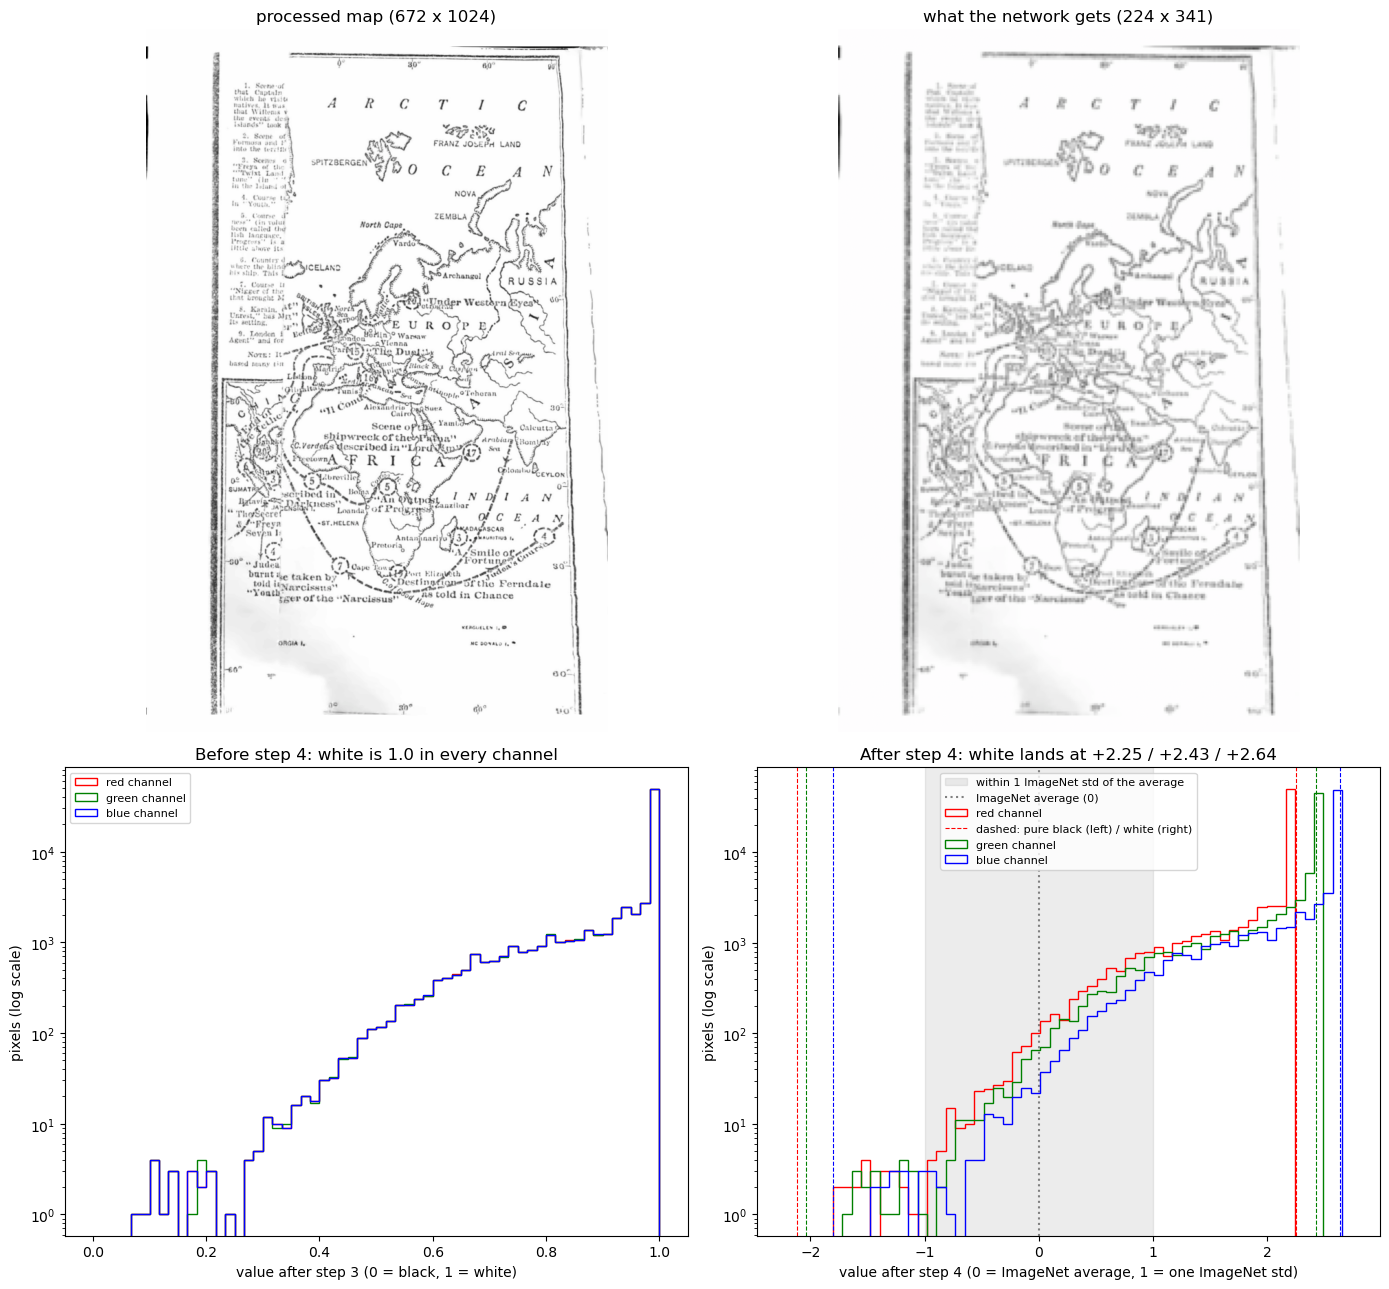

In [7]:
rng = np.random.default_rng(SEED)
example_path = PROC / splits["train"]["path"][rng.choice(np.where(is_original)[0])]
example = prepare_image(example_path)
after_step4 = example.numpy()                                                     # (3, height, width)
before_step4 = after_step4.transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN      # the 0-1 values from step 3
with Image.open(example_path) as img:
    original = np.asarray(img.convert("RGB"))

white = (1 - IMAGENET_MEAN) / IMAGENET_STD   # where a pure white pixel lands after step 4, per channel
black = (0 - IMAGENET_MEAN) / IMAGENET_STD   # where a pure black pixel lands
print("processed map:", original.shape, "(height, width, channels), values", original.min(), "to", original.max())
print("network input:", tuple(example.shape), "(channels, height, width), values",
      round(example.min().item(), 2), "to", round(example.max().item(), 2))
print(f"After step 4, pure white lands at red {white[0]:+.2f}, green {white[1]:+.2f}, blue {white[2]:+.2f}; "
      f"pure black at {black[0]:+.2f}, {black[1]:+.2f}, {black[2]:+.2f}")
print(f"On this page, {(before_step4 > 0.99).all(axis=2).mean():.0%} of the pixels are (almost) pure white, and "
      f"{(np.abs(after_step4) > 1).mean():.0%} of the values lie more than 1 ImageNet std from the ImageNet average")

fig, axes = plt.subplots(2, 2, figsize=(14, 13), gridspec_kw={"height_ratios": [1.5, 1]})
axes[0, 0].imshow(original)
axes[0, 0].set_title(f"processed map ({original.shape[1]} x {original.shape[0]})")
axes[0, 1].imshow(to_displayable(example))
axes[0, 1].set_title(f"what the network gets ({EMBED_SIZE[0]} x {EMBED_SIZE[1]})")
for ax in axes[0]:
    ax.axis("off")

channel_colors = ["red", "green", "blue"]
ax = axes[1, 0]
for channel, color in enumerate(channel_colors):
    ax.hist(before_step4[:, :, channel].ravel(), bins=np.linspace(0, 1, 61), histtype="step", color=color,
            label=f"{color} channel")
ax.set_yscale("log")
ax.set_xlabel("value after step 3 (0 = black, 1 = white)")
ax.set_ylabel("pixels (log scale)")
ax.set_title("Before step 4: white is 1.0 in every channel")
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.axvspan(-1, 1, color="gray", alpha=0.15, label="within 1 ImageNet std of the average")
ax.axvline(0, color="gray", linestyle=":", label="ImageNet average (0)")
bins = np.linspace(black.min() - 0.1, white.max() + 0.1, 61)
for channel, color in enumerate(channel_colors):
    ax.hist(after_step4[channel].ravel(), bins=bins, histtype="step", color=color, label=f"{color} channel")
    ax.axvline(white[channel], color=color, linestyle="--", linewidth=0.8)
    ax.axvline(black[channel], color=color, linestyle="--", linewidth=0.8,
               label="dashed: pure black (left) / white (right)" if channel == 0 else None)
ax.set_yscale("log")
ax.set_xlabel("value after step 4 (0 = ImageNet average, 1 = one ImageNet std)")
ax.set_ylabel("pixels (log scale)")
ax.set_title(f"After step 4: white lands at {white[0]:+.2f} / {white[1]:+.2f} / {white[2]:+.2f}")
ax.legend(fontsize=8, loc="upper center")
plt.tight_layout()
plt.show()

**Reading the histograms.** Left: pixel values before step 4, from 0 (black) to 1 (white). Most of the page is paper, so all three channels pile up near 1, and ink makes a thin tail toward 0. On gray or white paper the three lines lie on top of each other; on yellowed paper blue sits a little lower, because yellow has less blue.

Right: the same pixels after step 4. Normalizing only shifts and stretches each channel, so the shapes don't change, but each channel moves by a different amount: pure white lands at +2.25 (red), +2.43 (green) and +2.64 (blue), and pure black at about -2 (dashed lines). That is why one white page turns into three spikes - they are the same pixels, not three colors in the map. The shaded band is one ImageNet std either side of the ImageNet average, where the bulk of a typical photo's values fall. Our pages sit mostly far to the right of it. That is a first sign of the **domain gap**: old line drawings on paper look nothing like the photos the network learned from. The network still runs fine on them; the input just looks very different from what it learned on. Section 6 shows what the network makes of them.

## 6. The network step by step

PyTorch always works on **batches**: a stack of images with shape (batch size, channels, height, width). For one image, `unsqueeze(0)` adds a batch dimension of size 1.

`run_stages` runs ResNet-50 one stage at a time (the same steps `extractor(images)` runs internally) and keeps each stage's output, so we can watch the picture shrink while the number of channels grows. The last line checks that it gives the same embedding as `extractor`.

`torch.no_grad()` tells PyTorch not to keep the bookkeeping it would need for training (gradients). We only run images forward, so this saves memory and time.

In [8]:
def run_stages(images):
    """Run ResNet-50 one stage at a time and keep every stage's output. Same math as extractor(images)."""
    outputs = {"input": images}
    x = extractor.maxpool(extractor.relu(extractor.bn1(extractor.conv1(images))))
    outputs["stem (conv1 + max pool)"] = x
    for name in ["layer1", "layer2", "layer3", "layer4"]:
        x = getattr(extractor, name)(x)
        outputs[name] = x
    outputs["avgpool = embedding"] = torch.flatten(extractor.avgpool(x), 1)  # average over height and width
    return outputs


batch = example.unsqueeze(0).to(DEVICE)   # a batch of 1 image
with torch.no_grad():
    stages = run_stages(batch)
    embedding = extractor(batch)

print("run_stages gives the same embedding as extractor:",
      torch.allclose(stages["avgpool = embedding"], embedding, atol=1e-4))
pd.DataFrame([{"stage": name,
               "output shape (batch, channels, height, width)": tuple(out.shape),
               "numbers per image": f"{out[0].numel():,}"}
              for name, out in stages.items()])

run_stages gives the same embedding as extractor: True


,stage,"output shape (batch, channels, height, width)",numbers per image
0,input,"(1, 3, 341, 224)","229,152"
1,stem (conv1 + max pool),"(1, 64, 86, 56)","308,224"
2,layer1,"(1, 256, 86, 56)","1,232,896"
3,layer2,"(1, 512, 43, 28)","616,448"
4,layer3,"(1, 1024, 22, 14)","315,392"
5,layer4,"(1, 2048, 11, 7)","157,696"
6,avgpool = embedding,"(1, 2048)","2,048"


The 224 x 341 input ends up as a grid of 11 x 7 spots after layer4, each described by 2,048 numbers. Every spot "sees" a large patch of the page, so this grid is coarse. The average pool then averages each channel over the grid. That throws away *where* things are and keeps *how much* of each pattern the page contains, which suits a question like "is this a floor plan or a continent?" better than "where is the compass rose?".

### What does the full network think a map is?

Before using the embedding as our feature, we can put the removed last layer back on (`imagenet_head`) and ask the full network for its ImageNet guesses: embedding -> 1,000 scores -> softmax -> probabilities. This is only a demonstration; the classifier never uses these guesses.

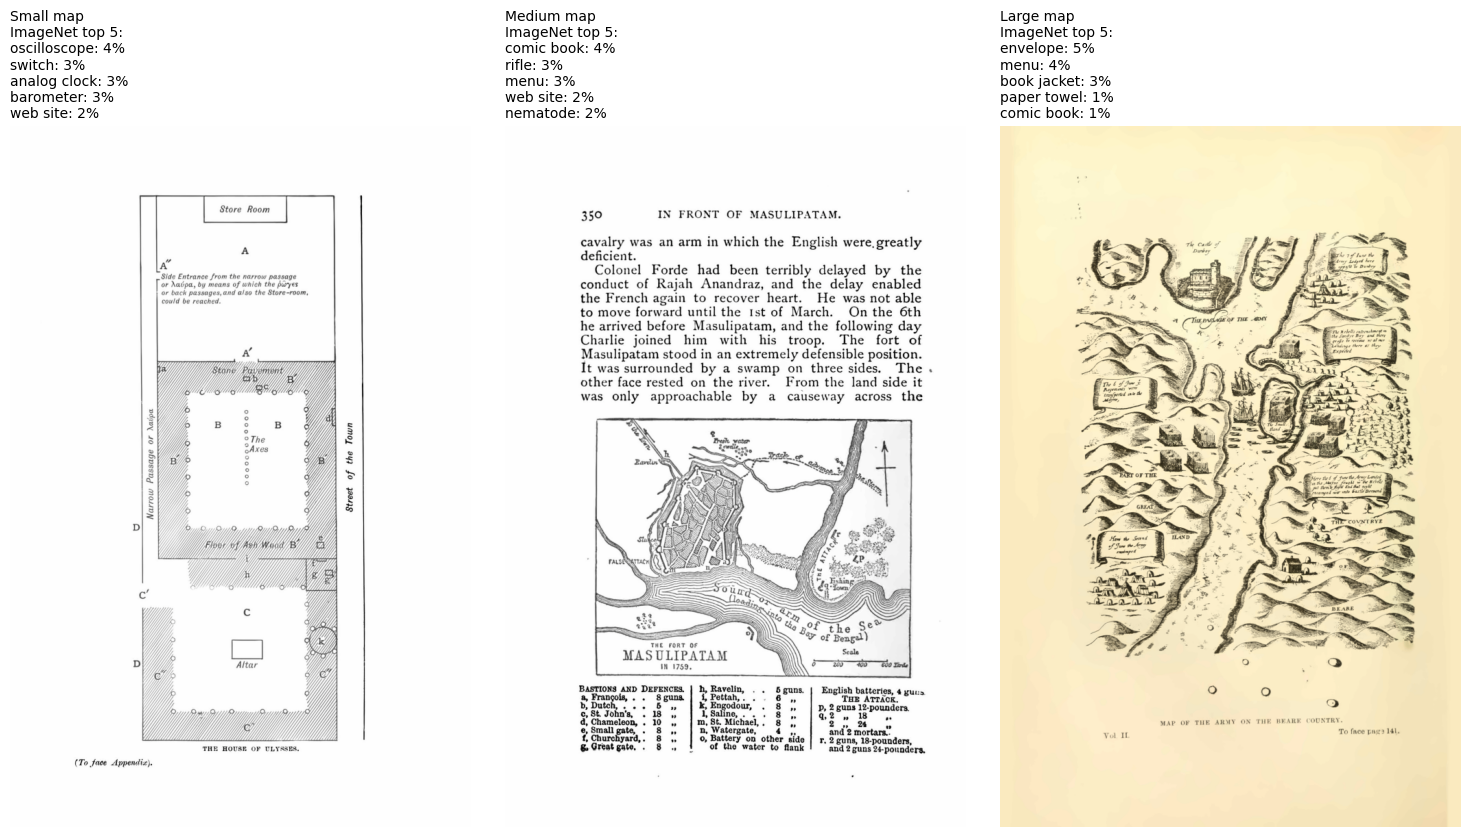

In [9]:
# One random train map per class (reused for the pictures in section 8)
rng = np.random.default_rng(SEED)
example_rows = {}
for class_id in range(3):
    example_rows[class_id] = rng.choice(np.where(is_original & (y["train"] == class_id))[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for class_id, ax in enumerate(axes):
    path = PROC / splits["train"].loc[example_rows[class_id], "path"]
    with torch.no_grad():
        emb = extractor(prepare_image(path).unsqueeze(0).to(DEVICE)).cpu()
        probabilities = torch.softmax(imagenet_head(emb), dim=1)[0]   # 1,000 probabilities that add up to 1
    top = torch.topk(probabilities, 5)
    guesses = [f"{IMAGENET_CATEGORIES[i]}: {p:.0%}" for p, i in zip(top.values.tolist(), top.indices.tolist())]

    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{CLASS_NAMES[class_id]} map\nImageNet top 5:\n" + "\n".join(guesses), fontsize=10, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Reading this.** ImageNet has no "map" category, so the network answers with the closest things it knows. A blind guess would give each category 0.1% (1 in 1,000).

On the 11/12 run the network was never confident: the top guess for each example was only 4-5%. The floor plan (Small) got instruments with dials and grids - oscilloscope, switch, analog clock, barometer. The fort plan printed under a page of text (Medium) and the regional map (Large) got printed matter - comic book, menu, envelope, book jacket, web site. The guesses are wrong, but they hint at what the embedding describes: how grid-like, text-heavy or paper-like a page looks. Section 8b checks this over all train maps.

## 7. Embeddings for every image

For each split, `embed_paths` prepares the images, sends them through the frozen network `BATCH_SIZE` at a time, and stacks the results into an array with one row per image and 2,048 columns. Batches are much faster than one image at a time, especially on a GPU. Nothing is learned here; the network only runs.

The result is saved to `data/features/resnet50_<split>.npz`, together with the list of image paths and the settings. On the next run, the saved file is used only if the manifest's rows, the settings, and the runs of `1-preprocessing` and `2-augment` that made the images all still match (`data_version`). So after re-running `1-preprocessing` or `2-augment` (or changing `EMBED_WIDTH` or `WEIGHTS`), the embeddings are recomputed automatically, even if the file names didn't change. Set `RECOMPUTE_EMBEDDINGS = True` to force it.

Other notebooks can load the same embeddings, in the same row order as the manifest:
```python
saved = np.load(ROOT / "data" / "features" / "resnet50_train.npz")
X_train = saved["X"]          # (n_train_images, 2048)
paths = saved["paths"]        # matches manifest rows where split == "train", in order
```

In [10]:
CACHE_INFO = {"weights": str(WEIGHTS), "embed_size": list(EMBED_SIZE), "layer": "avgpool (penultimate)"}


def embed_paths(paths, desc):
    """Run every image through the frozen network, BATCH_SIZE at a time. Returns (n_images x 2048 array, seconds)."""
    chunks = []
    start_time = time.perf_counter()
    for start in range(0, len(paths), BATCH_SIZE):
        batch_paths = paths[start : start + BATCH_SIZE]
        batch = torch.stack([prepare_image(PROC / p) for p in batch_paths]).to(DEVICE)
        with torch.no_grad():
            chunks.append(extractor(batch).cpu().numpy())
        done = start + len(batch_paths)
        print(f"\r{desc}: {done}/{len(paths)} images ({time.perf_counter() - start_time:.0f} s)", end="")
    print()
    return np.concatenate(chunks).astype(np.float32), time.perf_counter() - start_time


def cache_file(split_name):
    return FEATURE_DIR / f"resnet50_{split_name}.npz"


def load_saved(split_name, paths):
    """The saved embeddings for this split, or None if there are none or they're out of date."""
    file = cache_file(split_name)
    if RECOMPUTE_EMBEDDINGS or not file.exists():
        return None
    saved = np.load(file, allow_pickle=False)
    same_rows = saved["paths"].tolist() == list(paths)
    same_settings = json.loads(str(saved["info"])) == CACHE_INFO
    same_data = "data_version" in saved.files and str(saved["data_version"]) == data_version(split_name)
    if same_rows and same_settings and same_data:
        return saved["X"], float(saved["seconds"]), str(saved["device"])
    print(f"{file.name} is out of date (the manifest, the images or the settings changed) - recomputing")
    return None

In [11]:
X = {}               # X[split] = embeddings, one row per manifest row of that split
extract_seconds = {} # how long the network took per split (on extract_device)
extract_device = {}
for split_name in ["train", "val", "test"]:
    paths = splits[split_name]["path"].tolist()
    saved = load_saved(split_name, paths)
    if saved is not None:
        X[split_name], extract_seconds[split_name], extract_device[split_name] = saved
        print(f"{split_name}: loaded {len(paths)} saved embeddings from {cache_file(split_name).name}")
    else:
        X[split_name], extract_seconds[split_name] = embed_paths(paths, split_name)
        extract_device[split_name] = DEVICE
        np.savez(cache_file(split_name), X=X[split_name], paths=np.array(paths), info=json.dumps(CACHE_INFO),
                 data_version=data_version(split_name),
                 seconds=extract_seconds[split_name], device=DEVICE)
    print(f"   {split_name} embeddings: {X[split_name].shape[0]} images x {X[split_name].shape[1]} numbers")

assert X["train"].shape[1] == EMBED_DIM

train: 5001/5001 images (81 s)
   train embeddings: 5001 images x 2048 numbers
val: 292/292 images (4 s)
   val embeddings: 292 images x 2048 numbers
test: 290/290 images (4 s)
   test embeddings: 290 images x 2048 numbers


#### Timing the embedding (for the efficiency section)

The bulk run above may have used a GPU, while the features in `3-simple_model` were timed on one CPU core. To compare costs "assuming equal computational power", we time the network again on the **CPU, with one thread, one image at a time**, on the same number of training images (`N_TIMING_IMAGES`). The timer is split into loading + preparing the image and running the network, to show which part costs more. One untimed warm-up run comes first, because the first call is always slow.

In [12]:
timing_paths = splits["train"]["path"].tolist()[:N_TIMING_IMAGES]
threads_before = torch.get_num_threads()
extractor.to("cpu")
torch.set_num_threads(TIMING_CPU_THREADS)
try:
    prep_seconds = 0.0
    network_seconds = 0.0
    with torch.no_grad():
        extractor(prepare_image(PROC / timing_paths[0]).unsqueeze(0))   # warm-up, not timed
        for path in timing_paths:
            t = time.perf_counter()
            one_image = prepare_image(PROC / path).unsqueeze(0)
            prep_seconds += time.perf_counter() - t

            t = time.perf_counter()
            extractor(one_image)
            network_seconds += time.perf_counter() - t
finally:
    torch.set_num_threads(threads_before)   # put things back even if something above fails
    extractor.to(DEVICE)

prep_ms = 1000 * prep_seconds / len(timing_paths)
network_ms = 1000 * network_seconds / len(timing_paths)
embed_ms_per_image = prep_ms + network_ms
n_embedded = sum(len(splits[s]) for s in splits)
bulk_ms_per_image = 1000 * sum(extract_seconds.values()) / n_embedded

print(f"CPU, {TIMING_CPU_THREADS} thread, 1 image at a time: {embed_ms_per_image:.1f} ms per image "
      f"(load + prepare {prep_ms:.1f} ms, network {network_ms:.1f} ms)")
print(f"Bulk run above on {extract_device['train']}, batches of {BATCH_SIZE}: {bulk_ms_per_image:.1f} ms per image")

CPU, 1 thread, 1 image at a time: 158.7 ms per image (load + prepare 10.8 ms, network 147.9 ms)
Bulk run above on cuda, batches of 32: 16.1 ms per image


## 8. Look at the embeddings

Everything in this section uses **one row per train map** (`variant == "original"`), so augmented copies and rescans don't count twice - the same rule `3-simple_model` used for its plots. Val and test are not touched. Nothing fit in this section is used by the classifier. Because this section (like section 6) uses only the original train maps, which `2-augment` never touches, its numbers came out the same on the 11/4 run (3,070 training rows) and the 11/12 run (5,001).

### 8a. Three example maps

For the example map of each class from section 6:
- **Left:** what the network gets.
- **Middle: where the network responds.**
  - *What the numbers are:* layer4's output is a grid of 11 x 7 cells with 2,048 numbers per cell. Each number is one layer4 filter's output (after ReLU) at that cell: how strongly the pattern that filter learned is present there.
  - *What the color is:* the average of all 2,048 numbers in each cell. Bright = many filters firing strongly = the network finds a lot of structure there. It is not one filter and not the strongest one. It also knows nothing about our classes, so it is **not** "where the model sees Small".
  - *How it is placed on the map:* convolutions keep the layout (the top left of a layer's output comes from the top left of its input), and the picture is halved five times on the way down (stride 32 in total). So each cell sits over about a 32 x 32 patch of the input: 341 / 32 = about 11 rows, 224 / 32 = 7 columns. The code simply stretches the 11 x 7 map over the image; the smooth blending between cells is only for display. Each cell is influenced by more than its own patch (after 49 layers, in theory by the whole page), but mostly by the area near it, so the placement is roughly right but blurry.
- **Right: the embedding itself**, the 2,048 numbers laid out as a 32 x 64 grid only so they fit on screen; neighboring squares are not related. ResNet-50's last layers use ReLU, which turns negatives into 0, so the embedding has no negative numbers and many near-zero ones. Each number is one channel's average over the page: "how much of pattern #k is on this page".

The middle and right panels are two views of the same 2,048 x 11 x 7 block of numbers: the middle averages over the 2,048 filters (one number per place: *where* things happen), and the right averages over the 77 places (one number per filter: *how much* of each pattern the page has).

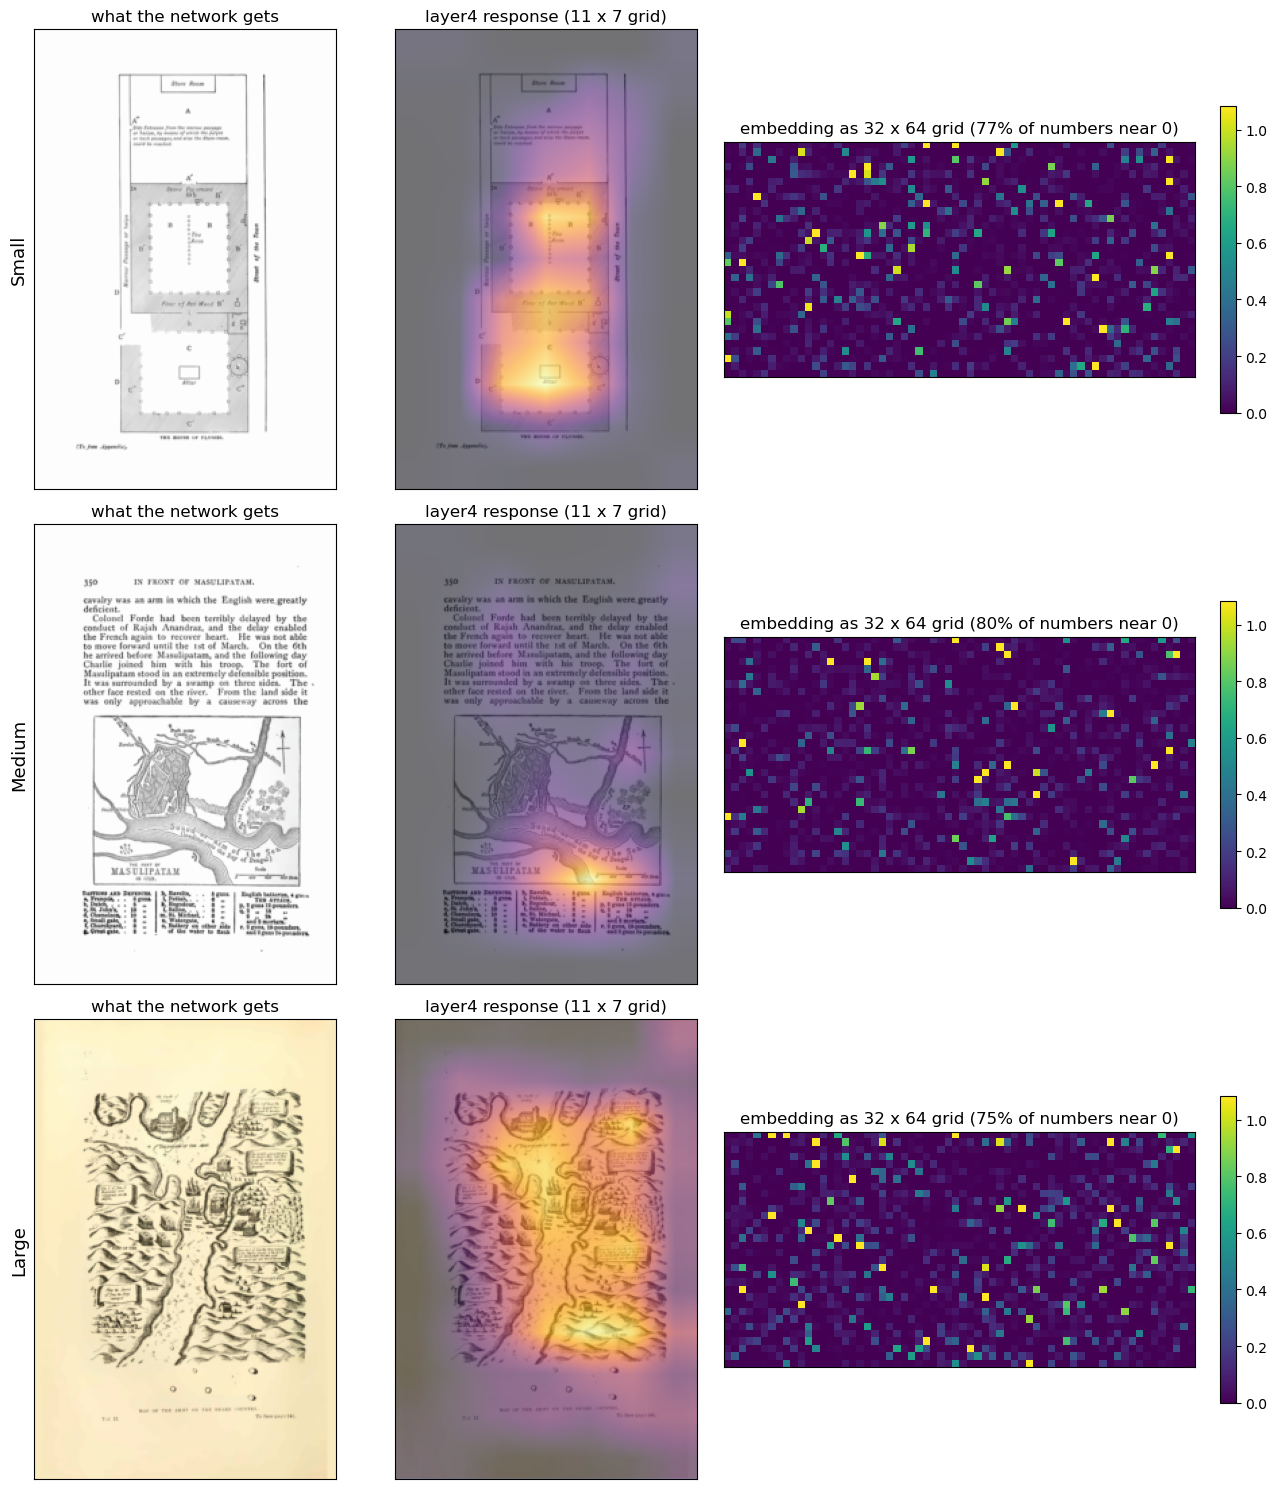

In [13]:
embedding_vmax = np.percentile(X["train"], 99)   # same color scale for all three embeddings

fig, axes = plt.subplots(3, 3, figsize=(13, 15), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for class_id in range(3):
    path = PROC / splits["train"].loc[example_rows[class_id], "path"]
    image_tensor = prepare_image(path)
    with torch.no_grad():
        stages = run_stages(image_tensor.unsqueeze(0).to(DEVICE))
    layer4 = stages["layer4"][0].cpu().numpy()            # (2048, grid height, grid width)
    emb = stages["avgpool = embedding"][0].cpu().numpy()  # (2048,)

    shown = to_displayable(image_tensor)
    height, width = shown.shape[:2]

    axes[class_id, 0].imshow(shown)
    axes[class_id, 0].set_title("what the network gets")

    axes[class_id, 1].imshow(shown)
    # stretch the 11 x 7 grid over the whole image; bilinear smoothing is only for display
    axes[class_id, 1].imshow(layer4.mean(axis=0), cmap="inferno", alpha=0.55,
                             extent=(0, width, height, 0), interpolation="bilinear")
    axes[class_id, 1].set_title(f"layer4 response ({layer4.shape[1]} x {layer4.shape[2]} grid)")

    picture = axes[class_id, 2].imshow(emb.reshape(32, 64), cmap="viridis", vmin=0, vmax=embedding_vmax)
    axes[class_id, 2].set_title(f"embedding as 32 x 64 grid ({(emb < 0.05).mean():.0%} of numbers near 0)")
    fig.colorbar(picture, ax=axes[class_id, 2], fraction=0.03)

    for ax in axes[class_id]:
        ax.set_xticks([])
        ax.set_yticks([])
    axes[class_id, 0].set_ylabel(CLASS_NAMES[class_id], fontsize=13)
plt.tight_layout()
plt.show()

**On the 11/12 run.** The floor plan (Small) lights up along the hatched walls and rows of columns, peaking at the altar room; plain floor and margins stay dark. The fort plan (Medium) peaks at the river mouth and the hatching at the bottom of the map, while the page of body text above it barely lights up. The regional map (Large) lights up most over the dense hatched waves and hills, plus the ships and castle at the top. In all three, the network responds to dense drawn texture rather than to text or empty paper, and about 75-80% of each embedding's numbers are near 0.

### 8b. ImageNet's guesses across all train maps

Section 6 showed the full network's guesses for three maps. Because the removed last layer is a simple linear layer, we can apply it to every saved embedding at almost no cost. The table shows the five most common top-1 ImageNet guesses for each class, with the share of that class's maps that got each guess. If the classes get different guesses, the embedding already "sees" a difference between them.

In [14]:
X_train_maps = X["train"][is_original]   # one row per train map

with torch.no_grad():
    top1 = imagenet_head(torch.from_numpy(X_train_maps)).argmax(dim=1).numpy()

guess_rows = {}
for class_id in range(3):
    names = pd.Series([IMAGENET_CATEGORIES[i] for i in top1[y_train_maps == class_id]])
    shares = names.value_counts(normalize=True).head(5)
    guesses = [f"{name} ({share:.0%})" for name, share in shares.items()]
    guesses += [""] * (5 - len(guesses))   # a class may get fewer than 5 different guesses
    guess_rows[f"{CLASS_NAMES[class_id]} (n={len(names)})"] = guesses

pd.DataFrame(guess_rows, index=[f"#{k}" for k in range(1, 6)]).T

,#1,#2,#3,#4,#5
Small (n=118),envelope (25%),crossword puzzle (12%),menu (12%),slide rule (8%),web site (7%)
Medium (n=248),envelope (22%),book jacket (21%),web site (16%),comic book (8%),menu (8%)
Large (n=992),envelope (29%),book jacket (17%),web site (15%),menu (10%),nematode (5%)


**On the 11/12 run** all three classes got mostly the same guesses: envelope (22-29% of each class's maps), book jacket, web site and menu. To the network, most of our maps are first of all "a printed page". The one class-specific hint is Small, the only class with crossword puzzle (12%) and slide rule (8%) in its top 5 - both grid-like objects, which fits floor plans' straight walls and room grids.

### 8c. Which embedding numbers differ most between the classes?

For each of the 2,048 numbers separately, the **ANOVA F statistic** (`f_classif`) compares how far apart the three class averages are with how spread out each class is. A large F means the classes' averages differ by much more than the noise within each class. Left: how F is distributed over all 2,048 numbers. Right: the three numbers with the largest F.

**How to read the count below.** It says how many numbers have class *averages* that clearly differ, one number at a time. That is not the same as how many numbers are "usable":
- *Significant is not the same as useful.* With 1,358 train maps, even a tiny gap between class averages passes p < 0.001. A number can differ on average and still overlap so much that it can't tell individual maps apart (see the boxplots).
- *Not significant is not the same as useless.* ANOVA looks at one number at a time and only compares averages. A number can help in combination with others (logistic regression uses combinations), or differ in spread rather than average.
- *The numbers are correlated.* Many of them probably measure the same few patterns (section 8d), so a count of 279 is not 279 separate pieces of information.
- *Chance hits.* With 2,048 tests at p < 0.001, about 2 numbers would pass by chance alone. The Bonferroni-corrected count (p < 0.05 / 2,048) is a stricter version that allows for running so many tests at once.

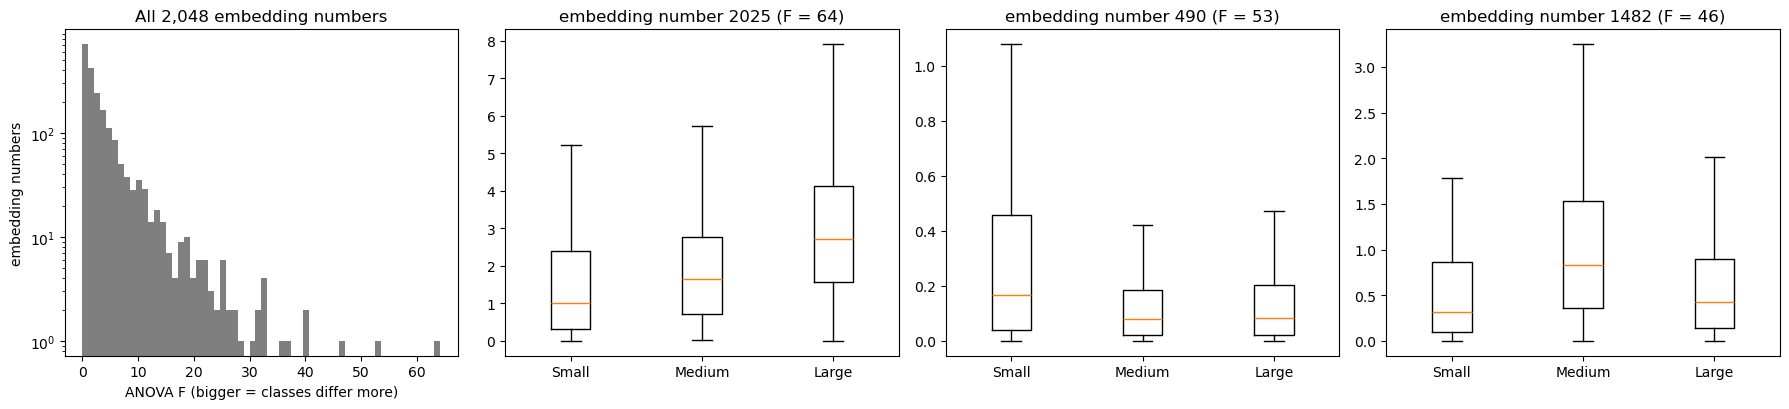

279 of 2048 embedding numbers (13.6%) differ between the classes at p < 0.001; chance alone would give about 2
151 pass the Bonferroni-corrected threshold (p < 0.05 / 2048 = 2.4e-05)


In [15]:
F, p_values = f_classif(X_train_maps, y_train_maps)
F = np.nan_to_num(F)   # a number that is 0 for every map gives F = NaN
top_dims = np.argsort(F)[::-1][:3]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].hist(F, bins=60, color="tab:gray")
axes[0].set_yscale("log")
axes[0].set_xlabel("ANOVA F (bigger = classes differ more)")
axes[0].set_ylabel("embedding numbers")
axes[0].set_title("All 2,048 embedding numbers")

for ax, dim in zip(axes[1:], top_dims):
    ax.boxplot([X_train_maps[y_train_maps == c, dim] for c in range(3)], showfliers=False)
    ax.set_xticks([1, 2, 3], CLASS_NAMES)
    ax.set_title(f"embedding number {dim} (F = {F[dim]:.0f})")
plt.tight_layout()
plt.show()

bonferroni = 0.05 / EMBED_DIM
n_significant = (p_values < 0.001).sum()
print(f"{n_significant} of {EMBED_DIM} embedding numbers ({n_significant / EMBED_DIM:.1%}) differ between the classes "
      f"at p < 0.001; chance alone would give about {0.001 * EMBED_DIM:.0f}")
print(f"{(p_values < bonferroni).sum()} pass the Bonferroni-corrected threshold (p < 0.05 / {EMBED_DIM} = {bonferroni:.1e})")

**On the 11/12 run**, 279 of the 2,048 numbers (about 14%) passed p < 0.001, against about 2 expected by chance, and 151 passed the stricter Bonferroni threshold. So a real but modest share of the embedding - roughly an eighth - differs on average between the classes, and none of those numbers separates them well on its own: even the strongest (number 2025, F = 64) has heavily overlapping boxplots. Each class has a few numbers that run higher for it (490 for Small, 1482 for Medium, 2025 for Large). The signal is real but weak and spread out, which is what the next two sections show from other angles.

### 8d. PCA: how much variation is there, and in how many directions?

**PCA** (principal component analysis) finds the directions in the 2,048-number space along which the maps vary the most. The first component is the single direction with the most spread, the second is the next-most at right angles to the first, and so on. The **explained variance** of a component is the share of all the variation it captures. We standardize first (mean 0, std 1 per number, the same step the classifier uses) and fit PCA on the train maps only.

**Left and middle: cumulative explained variance**, the same curve twice: the share of all variation that the first `n` components hold together. The red dots are the PCA sizes the search in section 9 tries.
- *Linear x-axis (left):* the classic diminishing-returns shape - steep at first, then flattening - because each extra component adds less than the one before.
- *Log x-axis (middle):* spaces the PCA sizes tried (each double the last) evenly. On a log axis diminishing returns look different: a straight line means every *doubling* of components adds about the same share, so each single component adds less and less. A curve that shoots up and then levels off would mean a few directions hold most of the information; a curve that keeps climbing means the variation is spread over many directions. The table under the plots gives the numbers.
- The curves stop at 512 because this PCA keeps at most 512 components. With 1,358 train maps there are only 1,357 directions in total, so the curve would reach 100% at 1,357 components, not 2,048.

**Right: every train map placed by its first two components**, colored by class.
- *How much it shows:* the axis labels give each component's share of the variation. Together the first two are usually a small share, so this picture shows only a slice of the embedding.
- *PCA never sees the labels.* It ranks directions by how much the pages vary along them, not by how well they separate the classes. A direction with very little variation could still separate the classes well.
- *Don't look for a trend between the axes.* The components are uncorrelated by construction, so the dots never form a diagonal line. What would mean something is colors sitting in different regions.
- *What overlap means:* component 1 stands for some property that varies a lot from page to page; each map's position on the x-axis is how much of it the page has. If that property were tied to scale (say, "how many straight walls at right angles"), floor plans would pile up at one end and continents at the other. If every color is spread across the whole range, knowing a map's component-1 value tells you little about its class: the biggest ways the pages differ have little to do with scale. (A made-up example to picture it: if component 1 measured how much printed text is on the page, it would vary hugely, but a floor plan, a town plan and a continent can each be a full-page plate or a small figure inside a page of text, so sorting by it would mix the classes. We haven't checked what component 1 really measures.)
- *No simple boundary is not the same as no signal.* The class averages can still be slightly offset in this view, too little to see by eye, and most of the separation the classifier finds can come from combining dozens of components, which no 2-D picture of PCA can show.

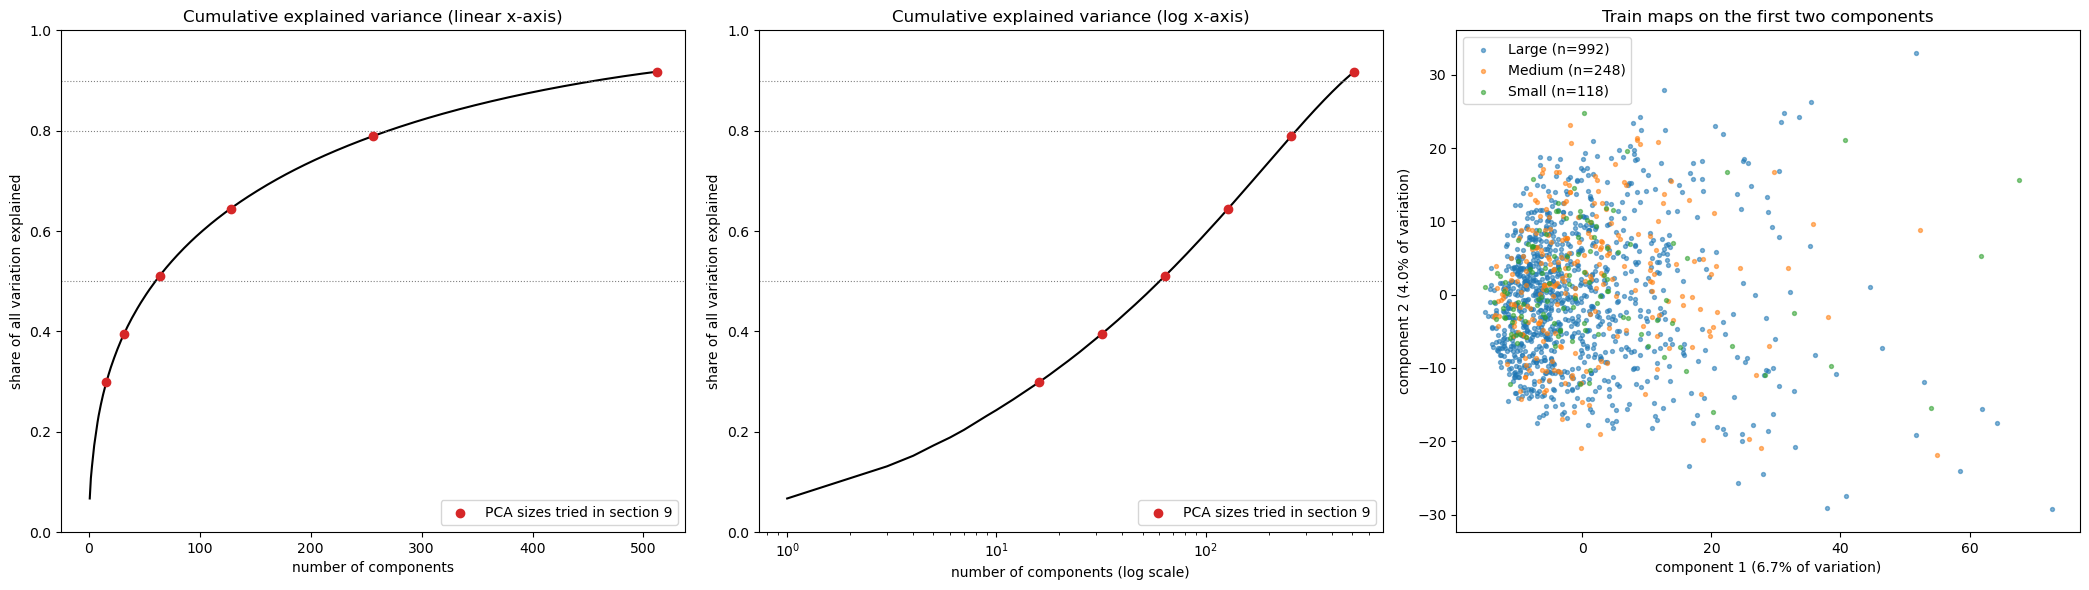

61 components explain 50% of the variation
270 components explain 80% of the variation
458 components explain 90% of the variation
The first two components together explain 10.7%


,components,cumulative share,added by this range,average per component
0,1-16,0.2990,0.2990,0.0187
1,17-32,0.3957,0.0968,0.0060
2,33-64,0.5109,0.1151,0.0036
3,65-128,0.6449,0.1340,0.0021
4,129-256,0.7891,0.1442,0.0011
5,257-512,0.9175,0.1285,0.0005


In [16]:
viz_scaler = StandardScaler().fit(X_train_maps)
X_train_maps_scaled = viz_scaler.transform(X_train_maps)
viz_pca = PCA(n_components=min(512, len(X_train_maps) - 1), random_state=SEED).fit(X_train_maps_scaled)
Z = viz_pca.transform(X_train_maps_scaled)              # each map's coordinates along the components
cumulative = np.cumsum(viz_pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
components = np.arange(1, len(cumulative) + 1)
marked = [d for d in PCA_DIMS if d <= len(cumulative)]
for ax, scale in zip(axes[:2], ["linear", "log"]):
    ax.plot(components, cumulative, color="black")
    if marked:
        ax.scatter(marked, cumulative[np.array(marked, dtype=int) - 1], color="tab:red", zorder=3,
                   label="PCA sizes tried in section 9")
    for level in [0.5, 0.8, 0.9]:
        ax.axhline(level, color="gray", linestyle=":", linewidth=0.8)
    ax.set_xscale(scale)
    ax.set_ylim(0, 1)
    ax.set_xlabel("number of components" + (" (log scale)" if scale == "log" else ""))
    ax.set_ylabel("share of all variation explained")
    ax.set_title(f"Cumulative explained variance ({scale} x-axis)")
    ax.legend(loc="lower right")

for class_id in [2, 1, 0]:   # Large first, so the rarer classes are drawn on top
    rows = y_train_maps == class_id
    axes[2].scatter(Z[rows, 0], Z[rows, 1], s=8, alpha=0.55, color=CLASS_COLORS[class_id],
                    label=f"{CLASS_NAMES[class_id]} (n={rows.sum()})")
axes[2].set_xlabel(f"component 1 ({viz_pca.explained_variance_ratio_[0]:.1%} of variation)")
axes[2].set_ylabel(f"component 2 ({viz_pca.explained_variance_ratio_[1]:.1%} of variation)")
axes[2].set_title("Train maps on the first two components")
axes[2].legend()
plt.tight_layout()
plt.show()

for level in [0.5, 0.8, 0.9]:
    if cumulative[-1] >= level:
        print(f"{np.searchsorted(cumulative, level) + 1} components explain {level:.0%} of the variation")
    else:
        print(f"{len(cumulative)} components explain {cumulative[-1]:.0%} of the variation (less than {level:.0%})")
print(f"The first two components together explain {cumulative[1]:.1%}")

# Diminishing returns in numbers: what each range of components adds
rows, previous_share, previous_n = [], 0.0, 0
for n in marked:
    added = cumulative[n - 1] - previous_share
    rows.append({"components": f"{previous_n + 1}-{n}", "cumulative share": cumulative[n - 1],
                 "added by this range": added, "average per component": added / (n - previous_n)})
    previous_share, previous_n = cumulative[n - 1], n
pd.DataFrame(rows).round(4)

**On the 11/12 run** the variation is spread out: 61 components explain half of it, 270 explain 80% and 458 explain 90%. Each doubling of the number of components adds about 10-15 percentage points, so the returns per component shrink steadily (from about 1.9% each for the first 16 to about 0.05% each for components 257-512), but the curve never levels off on the log axis: no small set of directions holds most of the information.

The first two components hold only 6.7% and 4.0% of the variation (about 11% together), and the three classes overlap completely along them - all three colors are in the dense cluster on the left and in the long tail on the right. So the two biggest ways the pages differ have little to do with scale, and the scale signal sits in smaller directions further down the list. That fits section 9, where the classifier needs dozens of components.

### 8e. t-SNE: who are each map's neighbors?

**t-SNE** squeezes the embeddings into 2 dimensions so that maps with similar embeddings land near each other. Unlike PCA it can bend and stretch space, so it can show clusters PCA's two straight directions miss. Only **who is near whom** means anything; the size of a cluster and the distance between clusters don't. `perplexity` is roughly how many neighbors each map pays attention to (30 is the usual default), and t-SNE runs on the first 50 PCA components from 8d, a standard step that removes noise and makes it faster.

The table below the plot puts a number on the neighborhoods: for each train map, the share of its 10 nearest neighbors (in the same 50-component space) that have the same class, next to the class's share of all maps, which is what random neighbors would give.

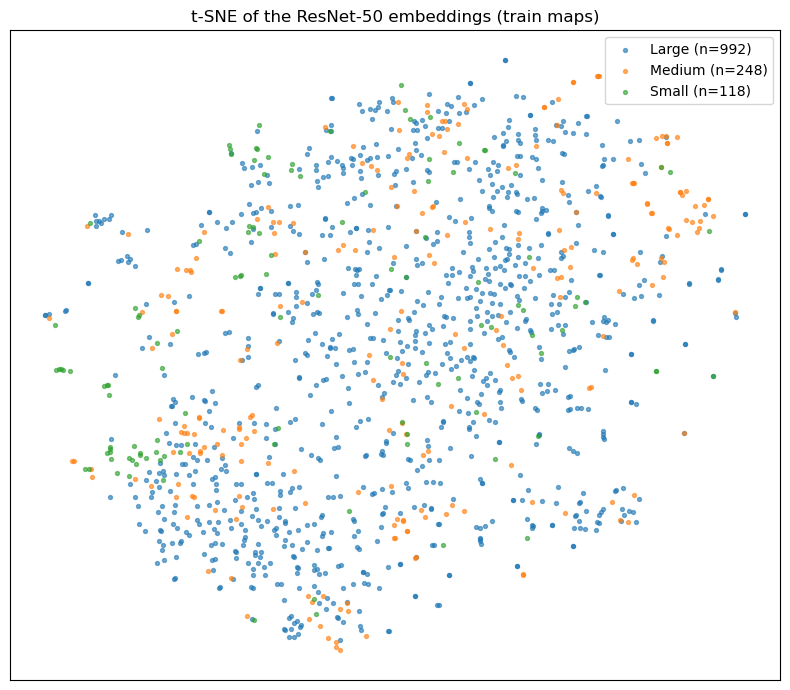

,share of 10 nearest neighbors with the same class,if neighbors were random (class share)
Small,0.262,0.087
Medium,0.333,0.183
Large,0.795,0.730


In [17]:
Z50 = Z[:, :50]
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
T2 = tsne.fit_transform(Z50)

fig, ax = plt.subplots(figsize=(8, 7))
for class_id in [2, 1, 0]:
    rows = y_train_maps == class_id
    ax.scatter(T2[rows, 0], T2[rows, 1], s=8, alpha=0.6, color=CLASS_COLORS[class_id],
               label=f"{CLASS_NAMES[class_id]} (n={rows.sum()})")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("t-SNE of the ResNet-50 embeddings (train maps)")
ax.legend()
plt.tight_layout()
plt.show()

# Neighbor check: 11 neighbors because each map's nearest neighbor is itself
neighbors = NearestNeighbors(n_neighbors=11).fit(Z50).kneighbors(Z50, return_distance=False)[:, 1:]
same_class = (y_train_maps[neighbors] == y_train_maps[:, None]).mean(axis=1)
pd.DataFrame({"share of 10 nearest neighbors with the same class": [same_class[y_train_maps == c].mean() for c in range(3)],
              "if neighbors were random (class share)": [np.mean(y_train_maps == c) for c in range(3)]},
             index=CLASS_NAMES).round(3)

**On the 11/12 run** there are no clean clusters per class: Large is spread everywhere, with only a few small clumps of Small near the edges. The neighbor table puts a number on it: a Small map's 10 nearest neighbors are Small 26% of the time, against 9% if neighbors were random (about 3x). Medium is 33% against 18%, and Large 80% against 73%. So the embedding places maps of the same scale somewhat closer together than chance, but weakly - the same message as 8c and 8d, and the clearest sign of signal in section 8 before any classifier is trained.

### What section 8 shows

To the network, our maps are mostly "printed pages" (8b). Its response follows dense drawn texture (8a), and the signal for scale is real but weak and spread out: about an eighth of the embedding numbers differ on average between the classes, none separates them on its own (8c), the variation is spread over hundreds of directions and the biggest ones aren't about scale (8d), and maps of the same scale are only somewhat more likely to be neighbors (8e). Compare with section 5 of `3-simple_model`, where the class averages of the simple features looked nearly the same.

## 9. Tuning on the validation set

**The model** is the same multinomial logistic regression as `3-simple_model` (one weight per input number for each class, then softmax), with one new step in front of it:

embedding (2,048) -> **standardize** -> **PCA** to `n` components (or none) -> logistic regression

**What "training" means here.** ResNet-50 stays frozen; nothing in it is learned. Training means fitting three small steps on the training embeddings (about 5,000: all variants, originals, rescans and augmented copies) and their labels:
- **StandardScaler:** learns the mean and standard deviation of each of the 2,048 numbers.
- **PCA:** learns the top `n` directions of variation. It doesn't use the labels.
- **Logistic regression:** learns 3 x `n` weights plus 3 biases, by minimizing log loss plus a penalty on large weights. C sets the penalty's strength, and class weighting sets how much each row counts.

Val and test embeddings only pass through the already-fitted steps, so nothing about them leaks into training.

**PCA as an extra layer.** PCA acts like a fixed, linear layer from 2,048 to `n` numbers in front of the softmax: each new number is a weighted sum of the 2,048 standardized ones, with no activation function. Unlike the regression after it, its weights don't come from the labels; PCA picks them to keep as much variation between pages as possible. Because the scaler, PCA and the regression are all linear, together they collapse into one linear map from the 2,048 numbers to the 3 class scores, with a built-in constraint: the regression may only use the `n` highest-variation directions. That restriction is a form of regularization, on top of the C penalty.

**What is tuned:**
- **PCA size** (`PCA_DIMS`): 16, 32, 64, 128, 256 or 512 components, or 2,048 = no PCA. With all 2,048 numbers the regression has over 6,000 weights for about 5,000 training rows, which is a lot of room to memorize them (including near-copies from augmentation). PCA keeps only the directions with the most variation, but it doesn't look at the labels, so it might throw away a small direction that matters for Small - which is why the size is tuned rather than fixed.
- **Class weighting:** none or `balanced`, as in `3-simple_model`. With equal class counts from `2-augment`, the two give identical fits.
- **C (regularization):** the same 13 values. Smaller C = stronger penalty on large weights = simpler model.

That is 7 x 2 x 13 = 182 settings. Each one: fit on train, score macro-F1 on val. The scaler and PCA are fit on **train only**, once per PCA size, and reused for every C and weighting (the result is the same as refitting them, just faster). The `converged` column records whether each fit finished before `MAX_ITER` steps (the notebook silences sklearn's convergence warnings, so this is where to look). The test set is not used in this section.

**Choosing a setting without overfitting the validation set.** With 182 settings and only 292 val maps (26 of them Small), the setting with the single highest val score partly won by luck. To see how much luck is involved, we score every setting on the same 200 **bootstrap resamples** of the val set - random subsets of the validation data: each resample draws 292 val maps at random, with replacement, so some maps count twice and some not at all. The spread of a setting's score across the resamples is its **standard error** (SE) - how much its val score would move with a different draw of val maps.

Then the **one-standard-error rule** (from Hastie, Tibshirani and Friedman, *The Elements of Statistical Learning*, section 7.10): among all settings whose val macro-F1 is within one SE of the best one, take the **simplest** - fewest PCA components first, then smallest C. Those settings are statistically tied with the winner, and the simplest of them is the least likely to have fit quirks of the val set. Set `SELECTION_RULE = "best"` to pick the plain highest val score instead, as `3-simple_model` does; both picks are printed either way.

`macro_f1_fast` computes the same number as sklearn's macro-F1 (the next cell checks this), but fast enough to run 182 x 200 times.

In [18]:
def macro_f1_fast(y_true, y_pred):
    """Macro-F1 for labels 0, 1, 2. Same result as f1_score(..., average="macro"), but much faster."""
    counts = np.bincount(3 * y_true + y_pred, minlength=9).reshape(3, 3)  # confusion matrix: rows = true, cols = predicted
    true_pos = np.diag(counts)
    false_pos = counts.sum(axis=0) - true_pos
    false_neg = counts.sum(axis=1) - true_pos
    denominator = 2 * true_pos + false_pos + false_neg
    f1_per_class = np.divide(2 * true_pos, denominator, out=np.zeros(3), where=denominator > 0)
    return f1_per_class.mean()


check_pred = np.random.default_rng(0).integers(0, 3, len(y["val"]))
assert np.isclose(macro_f1_fast(y["val"], check_pred),
                  f1_score(y["val"], check_pred, labels=[0, 1, 2], average="macro", zero_division=0))

# The same 200 resamples of the val maps are used for every setting, so the settings are compared fairly
n_val = len(y["val"])
val_resamples = np.random.default_rng(SEED).integers(0, n_val, size=(N_VAL_BOOTSTRAP, n_val))

In [19]:
search_rows = []
search_start = time.perf_counter()

scaler = StandardScaler().fit(X["train"])   # fit on train only
train_scaled = scaler.transform(X["train"])
val_scaled = scaler.transform(X["val"])

for n_dims in PCA_DIMS:
    # PCA, fit on train only (none for n_dims = 2,048)
    t = time.perf_counter()
    if n_dims < EMBED_DIM:
        pca = PCA(n_components=n_dims, random_state=SEED).fit(train_scaled)
        train_in = pca.transform(train_scaled)
        val_in = pca.transform(val_scaled)
    else:
        train_in, val_in = train_scaled, val_scaled
    pca_seconds = time.perf_counter() - t

    for class_weight in CLASS_WEIGHTS:
        weighting = "balanced" if class_weight == "balanced" else "none"
        for C in C_GRID:
            logreg = LogisticRegression(C=C, class_weight=class_weight, max_iter=MAX_ITER, random_state=SEED)
            t = time.perf_counter()
            logreg.fit(train_in, y["train"])
            fit_seconds = time.perf_counter() - t + pca_seconds   # PCA + regression, the full fitting cost

            val_pred = logreg.predict(val_in)
            resampled_scores = [macro_f1_fast(y["val"][rows], val_pred[rows]) for rows in val_resamples]
            search_rows.append({"pca_dims": n_dims, "weighting": weighting, "C": C,
                                "train_macro_f1": macro_f1_fast(y["train"], logreg.predict(train_in)),
                                "val_macro_f1": macro_f1_fast(y["val"], val_pred),
                                "val_f1_se": np.std(resampled_scores),
                                "converged": bool(np.max(logreg.n_iter_) < MAX_ITER),  # False = stopped at MAX_ITER
                                "fit_seconds": fit_seconds})

        best_here = max(r["val_macro_f1"] for r in search_rows if r["pca_dims"] == n_dims and r["weighting"] == weighting)
        print(f"PCA {n_dims:>4} | {weighting:<8} | best val macro-F1 = {best_here:.3f}   "
              f"({time.perf_counter() - search_start:.0f} s so far)")

search = pd.DataFrame(search_rows)

not_converged = search[~search["converged"]]
print(f"\n{len(not_converged)} of {len(search)} fits stopped at MAX_ITER = {MAX_ITER} before converging")
if len(not_converged):
    print(not_converged.groupby(["pca_dims", "weighting"])["C"]
          .agg(lambda c: ", ".join(f"{v:.0e}" for v in c)).rename("C values that didn't converge").to_string())

PCA   16 | none     | best val macro-F1 = 0.411   (0 s so far)
PCA   16 | balanced | best val macro-F1 = 0.411   (1 s so far)
PCA   32 | none     | best val macro-F1 = 0.421   (1 s so far)
PCA   32 | balanced | best val macro-F1 = 0.421   (1 s so far)
PCA   64 | none     | best val macro-F1 = 0.440   (2 s so far)
PCA   64 | balanced | best val macro-F1 = 0.440   (2 s so far)
PCA  128 | none     | best val macro-F1 = 0.466   (3 s so far)
PCA  128 | balanced | best val macro-F1 = 0.466   (3 s so far)
PCA  256 | none     | best val macro-F1 = 0.458   (5 s so far)
PCA  256 | balanced | best val macro-F1 = 0.458   (6 s so far)
PCA  512 | none     | best val macro-F1 = 0.482   (9 s so far)
PCA  512 | balanced | best val macro-F1 = 0.482   (11 s so far)
PCA 2048 | none     | best val macro-F1 = 0.472   (16 s so far)
PCA 2048 | balanced | best val macro-F1 = 0.472   (20 s so far)

0 of 182 fits stopped at MAX_ITER = 3000 before converging


In [20]:
# The plain best setting, and the one-standard-error choice
best = search.loc[search["val_macro_f1"].idxmax()]
threshold = best["val_macro_f1"] - best["val_f1_se"]
tied_with_best = search[search["val_macro_f1"] >= threshold]
simplest = tied_with_best.sort_values(["pca_dims", "C", "val_macro_f1"], ascending=[True, True, False]).iloc[0]
chosen = simplest if SELECTION_RULE == "one_se" else best


def pca_label(n_dims):
    return "no PCA" if n_dims >= EMBED_DIM else f"PCA {int(n_dims)}"


def describe(row):
    return (f"{pca_label(row['pca_dims'])}, weighting {row['weighting']}, C = {row['C']:.1e}: "
            f"val macro-F1 {row['val_macro_f1']:.3f} (SE {row['val_f1_se']:.3f}), train {row['train_macro_f1']:.3f}")


print("Highest val score:      ", describe(best))
print(f"Within one SE of it (val macro-F1 >= {threshold:.3f}): {len(tied_with_best)} of {len(search)} settings")
print("Simplest of those:      ", describe(simplest))
print(f"\nChosen ({SELECTION_RULE}):", describe(chosen))
print(f"Random guessing on val: {chance_val_f1:.3f}   Majority class on val: {majority_val_f1:.3f}")

# The 10 best settings by val score
(search.sort_values("val_macro_f1", ascending=False).head(10)
       .assign(C=lambda d: d["C"].map("{:.1e}".format)).round(3).reset_index(drop=True))

Highest val score:       PCA 512, weighting none, C = 2.2e+01: val macro-F1 0.482 (SE 0.036), train 0.908
Within one SE of it (val macro-F1 >= 0.446): 58 of 182 settings
Simplest of those:       PCA 128, weighting none, C = 2.2e-03: val macro-F1 0.450 (SE 0.033), train 0.737

Chosen (one_se): PCA 128, weighting none, C = 2.2e-03: val macro-F1 0.450 (SE 0.033), train 0.737
Random guessing on val: 0.332   Majority class on val: 0.281


,pca_dims,weighting,C,train_macro_f1,val_macro_f1,val_f1_se,converged,fit_seconds
0,512,none,2.2e+01,0.908,0.482,0.036,True,0.985
1,512,balanced,2.2e+01,0.908,0.482,0.036,True,0.964
2,512,balanced,1.0e+02,0.909,0.479,0.036,True,0.964
3,512,none,1.0e+02,0.909,0.479,0.036,True,0.964
4,512,none,4.6e+00,0.908,0.476,0.036,True,0.933
5,512,balanced,4.6e+00,0.908,0.476,0.036,True,0.969
6,512,balanced,2.2e-03,0.871,0.475,0.034,True,0.677
7,512,none,2.2e-03,0.871,0.475,0.034,True,0.669
8,2048,none,1.0e+02,1.000,0.472,0.034,True,0.254
9,2048,balanced,1.0e+02,1.000,0.472,0.034,True,0.258


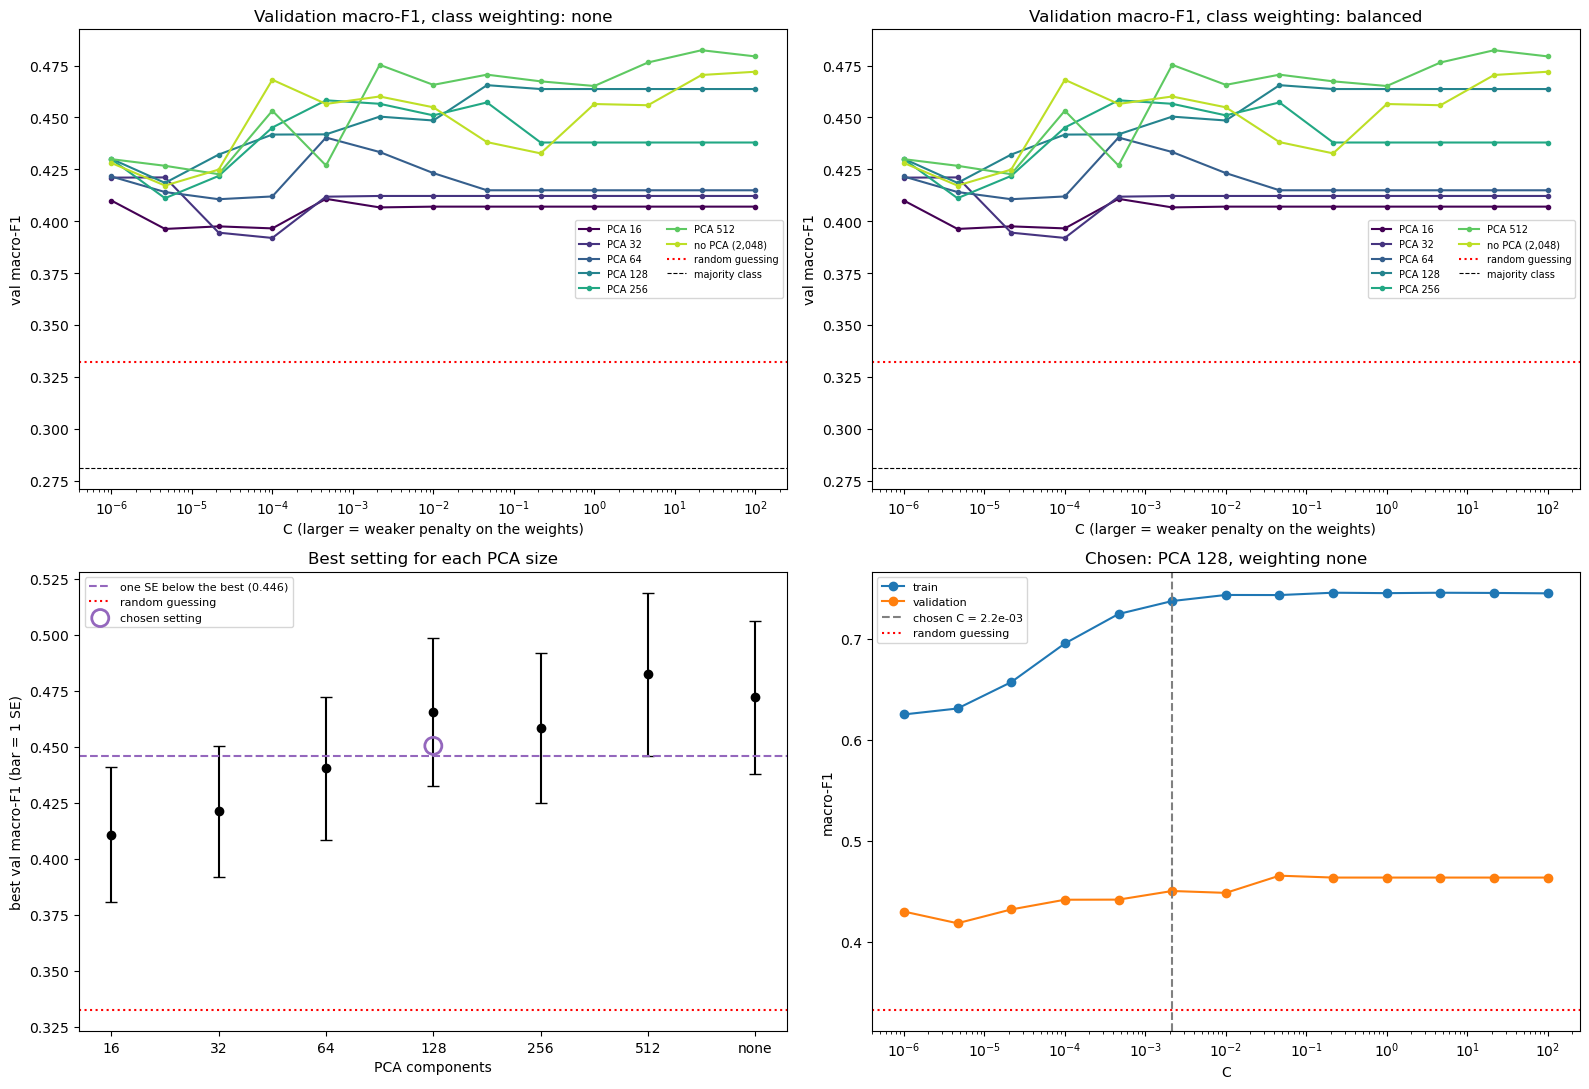

In [21]:
# Top: val macro-F1 across C for every PCA size, one panel per class weighting.
# Bottom left: the best val score of each PCA size, with its SE, and the one-SE line.
# Bottom right: train vs. val across C for the chosen PCA size and weighting (a big gap = overfitting).
fig = plt.figure(figsize=(16, 11))
size_colors = plt.cm.viridis(np.linspace(0, 0.9, len(PCA_DIMS)))

for panel, weighting in enumerate(["none", "balanced"]):
    ax = fig.add_subplot(2, 2, panel + 1)
    for n_dims, color in zip(PCA_DIMS, size_colors):
        curve = search[(search["pca_dims"] == n_dims) & (search["weighting"] == weighting)]
        label = "no PCA (2,048)" if n_dims == EMBED_DIM else f"PCA {n_dims}"
        ax.plot(curve["C"], curve["val_macro_f1"], marker="o", markersize=3, color=color, label=label)
    ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
    ax.axhline(majority_val_f1, color="black", linestyle="--", linewidth=0.8, label="majority class")
    ax.set_xscale("log")
    ax.set_xlabel("C (larger = weaker penalty on the weights)")
    ax.set_ylabel("val macro-F1")
    ax.set_title(f"Validation macro-F1, class weighting: {weighting}")
    ax.legend(fontsize=7, ncol=2)

ax = fig.add_subplot(2, 2, 3)
best_per_size = search.loc[search.groupby("pca_dims")["val_macro_f1"].idxmax()]
ax.errorbar(range(len(best_per_size)), best_per_size["val_macro_f1"], yerr=best_per_size["val_f1_se"],
            fmt="o", capsize=4, color="black")
ax.axhline(threshold, color="tab:purple", linestyle="--", label=f"one SE below the best ({threshold:.3f})")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
chosen_position = list(best_per_size["pca_dims"]).index(chosen["pca_dims"])
ax.scatter([chosen_position], [chosen["val_macro_f1"]], s=150, facecolors="none", edgecolors="tab:purple",
           linewidths=2, label="chosen setting", zorder=3)
ax.set_xticks(range(len(best_per_size)),
              ["none" if d == EMBED_DIM else str(d) for d in best_per_size["pca_dims"]])
ax.set_xlabel("PCA components")
ax.set_ylabel("best val macro-F1 (bar = 1 SE)")
ax.set_title("Best setting for each PCA size")
ax.legend(fontsize=8)

ax = fig.add_subplot(2, 2, 4)
curve = search[(search["pca_dims"] == chosen["pca_dims"]) & (search["weighting"] == chosen["weighting"])]
ax.plot(curve["C"], curve["train_macro_f1"], marker="o", label="train")
ax.plot(curve["C"], curve["val_macro_f1"], marker="o", label="validation")
ax.axvline(chosen["C"], color="gray", linestyle="--", label=f"chosen C = {chosen['C']:.1e}")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("macro-F1")
ax.set_title(f"Chosen: {pca_label(chosen['pca_dims'])}, weighting {chosen['weighting']}")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**How to read the tuning plots.**
- **Top:** each line is one PCA size. Where a line peaks shows the best C for that size.
- **Why most lines go flat at large C.** C sets how much fitting the training rows counts against keeping the weights small. Think of it as the length of a leash: the weights are pulled toward the fit with no penalty at all, and a short leash (small C) holds them back. Once the leash is longer than the distance to that fit, a longer leash changes nothing - same model, same val score, flat line. There is a limit to how far the weights go because a linear model's capacity is capped by its number of inputs: with 128 inputs it has 387 weights, which can't memorize 5,001 rows, so train macro-F1 tops out no matter how large C gets.
- **Where the overfitting shows.** In the middle of the C range, where the leash goes from tight to slack: there val drops while train keeps climbing (bottom right). The height of the flat part on the right is how the model does with no penalty at all - as overfit as it can get.
- **A line still climbing at the right edge** is still changing at the largest C tried. With many inputs and many near-copies of the same maps, the training rows become almost perfectly separable, so the weights "want" to grow very large and even C = 100 still holds them back; as the penalty fades on data like this, logistic regression drifts toward a maximum-margin boundary, like a linear SVM. A gain of about one SE there, at the edge of the grid, on a model with train macro-F1 near 1, should be read with caution. Check the `converged` count above too: a fit that stopped at `MAX_ITER` can look flat because it stopped early, not because it reached the no-penalty fit.
- **Bottom left:** if the error bars of several PCA sizes overlap, the val set can't really tell them apart, and the one-SE rule picks the smallest.

**On the 11/12 run.**
- *Best val score per PCA size:* 0.411 (16), 0.421 (32), 0.440 (64), 0.466 (128), 0.458 (256), 0.482 (512) and 0.472 (no PCA), with an SE of about 0.033-0.036. From 128 components up, the val set can't tell the sizes apart.
- *The plain best* was PCA 512 with C = 22: val 0.482, but train 0.908 - heavily overfit.
- *The one-SE rule* chose **PCA 128, no class weighting, C = 2.2e-3**: val 0.450, train 0.737. 58 of the 182 settings were within one SE of the best (val >= 0.446). PCA 64's best (0.440) fell just short, so 128 is the smallest size that qualifies.
- *Balanced weighting* gave exactly the same scores as no weighting: `2-augment` makes the three classes equal, so every row gets weight 1.
- *All 182 fits converged*, so the flat lines at large C are real plateaus, not fits that stopped early.
- *The chosen PCA size barely overfits:* as C grows, train climbs from about 0.62 to 0.74 and val from 0.43 to 0.465, and both go flat from about C = 0.05. With 128 inputs and 5,001 rows the regression has little room to memorize; the overfitting is in the bigger sizes (PCA 512 and no PCA reach train 0.9-1.0).

**What PCA bought, and what it didn't.** The chosen model uses 128 inputs instead of 2,048 - about 16x fewer regression weights (387 instead of 6,147) - with a val score tied with no PCA, and it overfits much less (train 0.737, against 0.908 for PCA 512 at C = 22). So PCA is a good way to simplify the classifier here. It does not make inference cheaper: every PCA component mixes all 2,048 numbers, so the full embedding is still needed, and the network is almost all of the cost (section 14). It also doesn't say which embedding numbers matter. And explained variance is not the way to choose its size: 128 components hold about 64% of the variation (section 8d), yet classify about as well as all 2,048. The variation thrown away is mostly unrelated to scale (scan tone, amount of text, paper texture); the val score, not explained variance, is the yardstick.

**Compared with the 11/4 run** (same split, but train rebalanced only to 590 / 1,240 / 1,240 rows): the best val score was higher at every PCA size (0.458-0.507 then, 0.411-0.482 now), and the one-SE rule chose PCA 64 at val 0.473. So the larger, equal augmentation did not help on val.

## 10. Final model and test set (run once)

Refit the chosen setting on train and score test. As in `3-simple_model`, don't go back and change anything above after seeing these numbers, or the test score stops being an honest estimate.

The three steps are packed into an sklearn **Pipeline**, so `fit` runs scale -> PCA -> regression on train, and `predict` applies the same three fitted steps to new embeddings. `"passthrough"` means "skip this step" (used when the chosen setting has no PCA).

In [22]:
FINAL_DIMS = int(chosen["pca_dims"])
FINAL_WEIGHTING = chosen["weighting"]
FINAL_C = float(chosen["C"])
final_class_weight = "balanced" if FINAL_WEIGHTING == "balanced" else None

final_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=FINAL_DIMS, random_state=SEED) if FINAL_DIMS < EMBED_DIM else "passthrough"),
    ("logreg", LogisticRegression(C=FINAL_C, class_weight=final_class_weight, max_iter=MAX_ITER, random_state=SEED)),
])

t = time.perf_counter()
final_model.fit(X["train"], y["train"])
fit_seconds = time.perf_counter() - t

t = time.perf_counter()
test_pred = final_model.predict(X["test"])
predict_seconds = time.perf_counter() - t

val_pred = final_model.predict(X["val"])   # same fit as in the search, so this matches the chosen val score
val_scores = get_scores(y["val"], val_pred)
test_scores = get_scores(y["test"], test_pred)
per_class_f1 = f1_score(y["test"], test_pred, labels=[0, 1, 2], average=None, zero_division=0)
n_test = len(y["test"])
two_step_errors = int((np.abs(test_pred - y["test"]) == 2).sum())
n_errors = int((test_pred != y["test"]).sum())

print(f"Chosen setting: {pca_label(FINAL_DIMS)}, class weighting {FINAL_WEIGHTING}, C = {FINAL_C:.2e}  ({SELECTION_RULE} rule)")
print(f"Val macro-F1:      {val_scores['macro_f1']:.3f}   val macro MAE: {val_scores['macro_mae']:.3f} steps")
print(f"Test macro-F1:     {test_scores['macro_f1']:.3f}   (random guessing: {chance_test_f1:.3f}, majority class: {majority_test_f1:.3f})")
print(f"Test macro MAE:    {test_scores['macro_mae']:.3f} steps   (random guessing: {chance_test_mae:.3f}, "
      f"majority class: {majority_test_mae:.3f}; lower is better)")
print(f"Test balanced acc: {test_scores['balanced_acc']:.3f}")
print(f"Test accuracy:     {test_scores['accuracy']:.3f}")
print(f"Two-step errors (Small called Large, or Large called Small): {two_step_errors} of {n_errors} errors")
print(f"Predicted per class (Small, Medium, Large): {np.bincount(test_pred, minlength=3)}   "
      f"actual: {np.bincount(y['test'], minlength=3)}")
print()

# precision = of the maps it called Small, how many really were Small
# recall    = of the real Small maps, how many it found
# support   = how many test maps are in that class
print(classification_report(y["test"], test_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=3, zero_division=0))

Chosen setting: PCA 128, class weighting none, C = 2.15e-03  (one_se rule)
Val macro-F1:      0.457   val macro MAE: 0.691 steps
Test macro-F1:     0.461   (random guessing: 0.332, majority class: 0.282)
Test macro MAE:    0.744 steps   (random guessing: 0.941, majority class: 1.000; lower is better)
Test balanced acc: 0.489
Test accuracy:     0.603
Two-step errors (Small called Large, or Large called Small): 44 of 115 errors
Predicted per class (Small, Medium, Large): [ 42  64 184]   actual: [ 25  53 212]

              precision    recall  f1-score   support

       Small      0.214     0.360     0.269        25
      Medium      0.359     0.434     0.393        53
       Large      0.777     0.675     0.722       212

    accuracy                          0.603       290
   macro avg      0.450     0.489     0.461       290
weighted avg      0.652     0.603     0.623       290



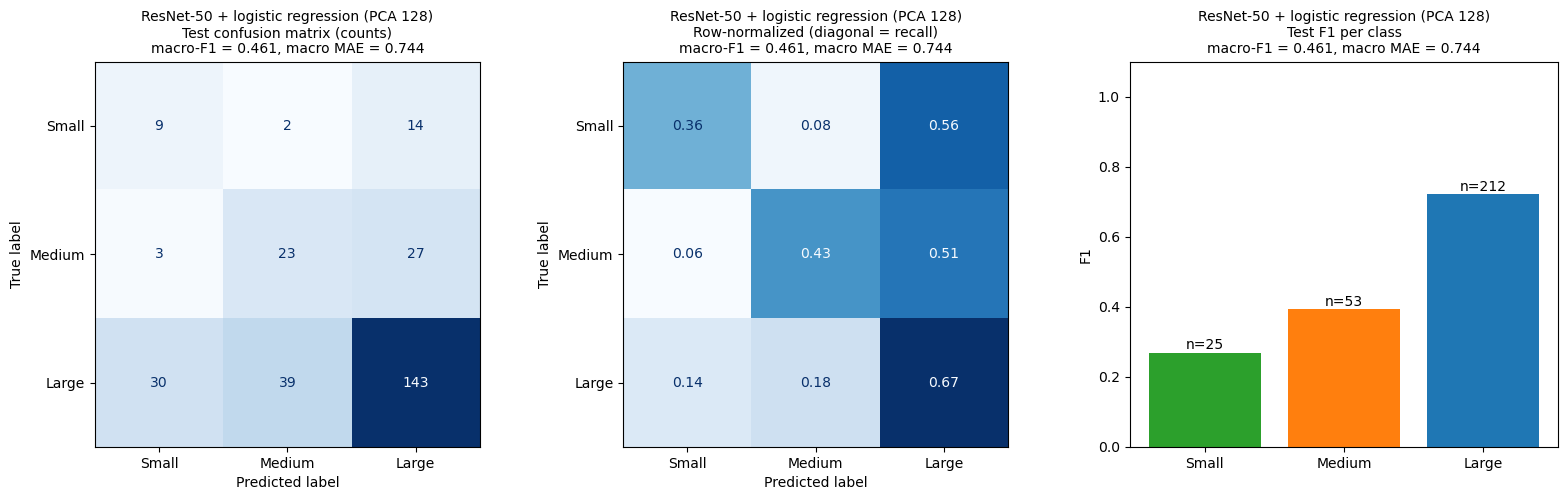

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# The model and its scores go in every title, so each panel can be cropped on its own for slides
model_name = f"ResNet-50 + logistic regression ({pca_label(FINAL_DIMS)})"
score_line = f"macro-F1 = {test_scores['macro_f1']:.3f}, macro MAE = {test_scores['macro_mae']:.3f}"

counts = confusion_matrix(y["test"], test_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(counts, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{model_name}\nTest confusion matrix (counts)\n{score_line}", fontsize=10)

# Each row adds up to 1, so the diagonal is the recall of that class
rates = confusion_matrix(y["test"], test_pred, labels=[0, 1, 2], normalize="true")
ConfusionMatrixDisplay(rates, display_labels=CLASS_NAMES).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title(f"{model_name}\nRow-normalized (diagonal = recall)\n{score_line}", fontsize=10)

class_counts = np.bincount(y["test"], minlength=3)
bars = axes[2].bar(CLASS_NAMES, per_class_f1, color=CLASS_COLORS)
for k, bar in enumerate(bars):
    axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"n={class_counts[k]}", ha="center")
axes[2].set_ylim(0, 1.1)
axes[2].set_ylabel("F1")
axes[2].set_title(f"{model_name}\nTest F1 per class\n{score_line}", fontsize=10)

plt.tight_layout()
plt.show()

**On the 11/12 run** the test macro-F1 was 0.461, against 0.457 on val. (The search in section 9 scored the same setting 0.450 on val. The difference is numerical: the refit's pipeline projects the training rows with PCA's `fit_transform`, the search with `fit` then `transform`. The two agree only up to rounding, which moves a few borderline val predictions.)

The errors now lean toward **Small**: the model predicted Small 42 times for 25 Small test maps, and 30 of the 212 Large maps were called Small. Training rows are rebalanced to 1,667 per class (33 / 33 / 33%), so the model learned that Small is as common as Large, while in val and test it is about eight times rarer. Large called Medium is still the most common single mistake (39 maps), and Medium was predicted 64 times for 53 Medium maps. Accuracy (0.603) lands below always-Large (0.731). Section 13 tests the class-mix explanation.

The model found 9 of the 25 Small maps. 14 Small maps were called Large and 30 Large maps called Small - 44 two-step errors out of 115 (38%). Macro MAE is 0.74 steps: Small maps are on average 1.2 steps off, Medium 0.57 and Large 0.47.

**Compared with the 11/4 run** (same split; train rebalanced only to 590 / 1,240 / 1,240): test macro-F1 was 0.481, macro MAE 0.65 and there were 20 two-step errors. Then the model over-predicted Medium (106 predictions for 53 Medium maps) and under-predicted Small (18 for 25). Equal class counts moved the over-prediction from Medium to Small and more than doubled the two-step errors, mostly Large maps called Small (9 then, 30 now).

## 11. Comparison to the baselines and the simple features

- A **bootstrap** over the test maps puts a 95% interval on the test macro-F1 (the test set has only about 25 Small maps, so the score is noisy).
- The **share of random-guessing runs** that score at least as high as the model says how likely its edge is to be luck.
- **`3-simple_model`'s result** is loaded from `data/results/3-simple_model.json` (saved by that notebook's section 9). If the file is missing, its 11/12 numbers are used, copied by hand.
- **A paired test against `3-simple_model`.** The two models' bootstrap intervals overlap, but that comparison throws away the fact that both were scored on the *same* 290 test maps. The paired version resamples the test maps once per round and scores both models on each draw, so the luck of the draw cancels out. If the 95% interval of the difference excludes 0, the gap between the features is real, not a lucky test set. It needs `3-simple_model`'s saved test predictions.

Then a per-class table shows which classes any edge comes from, in F1 and in average steps off.

In [24]:
# ---- Bootstrap intervals for this model ----
rng = np.random.default_rng(SEED)
boot_f1, boot_mae = [], []
for _ in range(N_BOOTSTRAP):
    rows = rng.integers(0, n_test, n_test)
    boot_f1.append(macro_f1_fast(y["test"][rows], test_pred[rows]))
    boot_mae.append(macro_mae(y["test"][rows], test_pred[rows]))
model_low, model_high = np.percentile(boot_f1, [2.5, 97.5])
mae_low, mae_high = np.percentile(boot_mae, [2.5, 97.5])
share_as_good = (guess_f1["test"] >= test_scores["macro_f1"]).mean()

# ---- 3-simple_model's saved results (run that notebook first) ----
simple_json = RESULTS_DIR / "3-simple_model.json"
if simple_json.exists():
    simple_results = json.loads(simple_json.read_text())
    simple_source = f"3-simple_model, run {simple_results['run_date']}"
else:
    print("data/results/3-simple_model.json not found - using 3-simple_model's 11/12 numbers, copied by hand. "
          "Run 3-simple_model.ipynb to compare against its saved results.")
    simple_results = {"feature": "ink", "class_weight": "none", "test_macro_f1": 0.383, "test_macro_f1_95ci": [0.324, 0.440],
                      "test_accuracy": 0.434, "test_macro_mae": 0.794, "train_cost_seconds": 112.0,
                      "inference_ms_per_image": 22.4}
    simple_source = "3-simple_model, 11/12 run (copied by hand)"

comparison = pd.DataFrame([
    {"model": "majority_class", "test_macro_f1": majority_test_f1, "95% range": "-",
     "test_macro_mae": majority_test_mae, "test_accuracy": baseline_value("majority_class", "test", "accuracy")},
    {"model": "random_guess (mean)", "test_macro_f1": chance_test_f1,
     "95% range": f"{chance_test_range[0]:.3f} - {chance_test_range[1]:.3f} (across random runs)",
     "test_macro_mae": chance_test_mae, "test_accuracy": baseline_value("random_guess (mean)", "test", "accuracy")},
    {"model": f"simple features ({simple_results['feature']}) + logistic regression [{simple_source}]",
     "test_macro_f1": simple_results["test_macro_f1"],
     "95% range": "{:.3f} - {:.3f} (bootstrap)".format(*simple_results["test_macro_f1_95ci"]),
     "test_macro_mae": simple_results["test_macro_mae"], "test_accuracy": simple_results["test_accuracy"]},
    {"model": f"ResNet-50 embedding + logistic regression ({pca_label(FINAL_DIMS)}, {FINAL_WEIGHTING})",
     "test_macro_f1": test_scores["macro_f1"], "95% range": f"{model_low:.3f} - {model_high:.3f} (bootstrap)",
     "test_macro_mae": test_scores["macro_mae"], "test_accuracy": test_scores["accuracy"]},
])

print(f"Test macro-F1 {test_scores['macro_f1']:.3f}: {share_as_good:.1%} of the {N_GUESS_SEEDS} "
      f"random-guessing runs score at least this high.")
print("Rough guide: over 5% = could easily be luck, 1-5% = borderline, under 1% = clearly better than guessing.")
print(f"Test macro MAE {test_scores['macro_mae']:.3f} steps (bootstrap 95% interval {mae_low:.3f} - {mae_high:.3f}); lower is better.")
print(f"Val macro-F1 {val_scores['macro_f1']:.3f} vs. test {test_scores['macro_f1']:.3f}: "
      f"a test score far below val would mean the setting fit the val set by luck.")
comparison.round(3)

Test macro-F1 0.461: 0.0% of the 1000 random-guessing runs score at least this high.
Rough guide: over 5% = could easily be luck, 1-5% = borderline, under 1% = clearly better than guessing.
Test macro MAE 0.744 steps (bootstrap 95% interval 0.607 - 0.876); lower is better.
Val macro-F1 0.457 vs. test 0.461: a test score far below val would mean the setting fit the val set by luck.


,model,test_macro_f1,95% range,test_macro_mae,test_accuracy
0,majority_class,0.282,-,1.000,0.731
1,random_guess (mean),0.332,0.279 - 0.389 (across random runs),0.941,0.574
2,simple features (ink) + logistic regression [3...,0.383,0.324 - 0.440 (bootstrap),0.794,0.434
3,ResNet-50 embedding + logistic regression (PCA...,0.461,0.395 - 0.525 (bootstrap),0.744,0.603


In [25]:
# ---- Paired test: ResNet-50 vs. simple features, on the same test maps ----
simple_test_pred = None
simple_pred_file = RESULTS_DIR / "3-simple_model_test_predictions.csv"
if not simple_pred_file.exists():
    print("data/results/3-simple_model_test_predictions.csv not found - run 3-simple_model.ipynb for the paired test")
else:
    saved = pd.read_csv(simple_pred_file)
    matched = splits["test"]["path"].map(dict(zip(saved["path"], saved["pred"])))
    saved_labels = splits["test"]["path"].map(dict(zip(saved["path"], saved["label"])))
    if matched.isna().any() or (saved_labels.to_numpy() != y["test"]).any():
        print("3-simple_model's saved predictions are for a different test set or labels - re-run 3-simple_model "
              "after 1-preprocessing, then this cell")
    else:
        simple_test_pred = matched.to_numpy().astype(int)

if simple_test_pred is not None:
    rng = np.random.default_rng(SEED)
    f1_gain, mae_gain = [], []
    for _ in range(N_BOOTSTRAP):
        rows = rng.integers(0, n_test, n_test)   # one draw of test maps, scored for both models
        f1_gain.append(macro_f1_fast(y["test"][rows], test_pred[rows]) - macro_f1_fast(y["test"][rows], simple_test_pred[rows]))
        mae_gain.append(macro_mae(y["test"][rows], simple_test_pred[rows]) - macro_mae(y["test"][rows], test_pred[rows]))
    f1_gain, mae_gain = np.array(f1_gain), np.array(mae_gain)

    simple_f1 = macro_f1_fast(y["test"], simple_test_pred)
    simple_mae = macro_mae(y["test"], simple_test_pred)
    print(f"Macro-F1:  ResNet-50 {test_scores['macro_f1']:.3f} vs. simple {simple_f1:.3f}: "
          f"gain {test_scores['macro_f1'] - simple_f1:+.3f}, paired 95% interval "
          f"{np.percentile(f1_gain, 2.5):+.3f} to {np.percentile(f1_gain, 97.5):+.3f}; "
          f"ResNet-50 no better in {(f1_gain <= 0).mean():.1%} of resamples")
    print(f"Macro MAE: ResNet-50 {test_scores['macro_mae']:.3f} vs. simple {simple_mae:.3f} steps: "
          f"{simple_mae - test_scores['macro_mae']:.3f} fewer steps off, paired 95% interval "
          f"{np.percentile(mae_gain, 2.5):+.3f} to {np.percentile(mae_gain, 97.5):+.3f}")

    # Which maps each model gets right
    resnet_right = test_pred == y["test"]
    simple_right = simple_test_pred == y["test"]
    agreement = pd.DataFrame({"both right": [(resnet_right & simple_right).sum()],
                              "only ResNet-50 right": [(resnet_right & ~simple_right).sum()],
                              "only simple right": [(~resnet_right & simple_right).sum()],
                              "both wrong": [(~resnet_right & ~simple_right).sum()]}, index=["test maps"])
    display(agreement)

Macro-F1:  ResNet-50 0.461 vs. simple 0.383: gain +0.079, paired 95% interval +0.007 to +0.145; ResNet-50 no better in 1.5% of resamples
Macro MAE: ResNet-50 0.744 vs. simple 0.794 steps: 0.050 fewer steps off, paired 95% interval -0.124 to +0.224


,both right,only ResNet-50 right,only simple right,both wrong
test maps,96,79,30,85


In [26]:
per_class = pd.DataFrame({
    "model F1": per_class_f1,
    "random guessing F1": guess_per_class["test"],
    "majority class F1": f1_score(y["test"], majority_pred["test"], labels=[0, 1, 2], average=None, zero_division=0),
    "test maps": np.bincount(y["test"], minlength=3),
}, index=CLASS_NAMES)
if simple_test_pred is not None:
    per_class.insert(1, "simple features F1",
                     f1_score(y["test"], simple_test_pred, labels=[0, 1, 2], average=None, zero_division=0))
per_class["model minus random"] = per_class["model F1"] - per_class["random guessing F1"]
per_class["model steps off"] = steps_off_per_class(y["test"], test_pred)          # lower is better
per_class["random guessing steps off"] = guess_steps["test"]                     # majority class: 2, 1, 0
per_class.round(3)

,model F1,simple features F1,random guessing F1,majority class F1,test maps,model minus random,model steps off,random guessing steps off
Small,0.269,0.185,0.083,0.000,25,0.185,1.200,1.648
Medium,0.393,0.425,0.183,0.000,53,0.210,0.566,0.816
Large,0.722,0.539,0.730,0.845,212,-0.008,0.467,0.358


**Results of the 11/12 run.**
- **Better than guessing:** test macro-F1 0.461, with a bootstrap interval of 0.395 - 0.525 that sits entirely above the random-guessing range (0.28 - 0.39). None of the 1,000 random runs scored that high. On macro MAE it is 0.74 steps, against about 0.94 for random guessing and 1.0 for always-Large.
- **Against the simple features:** +0.079 macro-F1 over `3-simple_model` (`ink`, 0.383). The two models' own bootstrap intervals overlap, but the paired test, which scores both on the same draws of test maps, puts the gain at +0.007 to +0.145 (95%), and ResNet-50 came out no better in only 1.5% of resamples. So the gain is real, though its lower end is close to 0. On macro MAE the difference is small (0.744 vs. 0.794 steps, paired interval -0.12 to +0.22), so that part could be luck.
- **Different maps right:** ResNet-50 gets 175 of the 290 test maps right, the simple features 126 (96 both, 79 only ResNet-50, 30 only the simple features). Most of the gap is Large maps, 81 of which the simple features call Small.
- **Where the edge comes from:** Small (F1 0.27, against 0.08 for guessing and 0.19 for the simple features) and Large (0.72 against 0.54 for the simple features, though still no better than guessing's 0.73). On Medium the simple features did slightly better (0.43 vs. 0.39).
- **Generalizability:** test (0.461) came in at val's level (0.457), so the tuning did not overfit the val set: the one-SE rule passed over the overfit PCA 512 setting (train 0.908), and the setting it chose held up. Section 16 discusses why the classes differ.

## 12. Which maps does it get wrong?

The scores say how often the model is wrong; this section shows what the mistakes look like. For each of the four most important kinds of mistake, the test maps the model was **most confident** about, with the probability it gave the wrong class. Looking at test images after scoring doesn't change the model, so it doesn't spend the test set.

- **Large called Medium:** the most common mistake. Do these look like town plans (dense streets and labels on a regional map), or are they pages with a lot of text?
- **Medium called Large:** town plans that look like regions, e.g. with coastlines or rivers.
- **Small called Large:** the worst mistake (two steps off). Estates and gardens drawn like landscapes?
- **Small called Medium:** large houses or estates that look like towns.

Then a check on the labels: maps whose scans got **different labels from Gemini** (`label_conflict`, see the README) are the ones whose true scale is hardest to pin down. If the model is wrong much more often on them, part of its error is label noise rather than a weakness of the feature.

Large called Medium: 39 test maps
Medium called Large: 27 test maps
Small called Large: 14 test maps
Small called Medium: 2 test maps


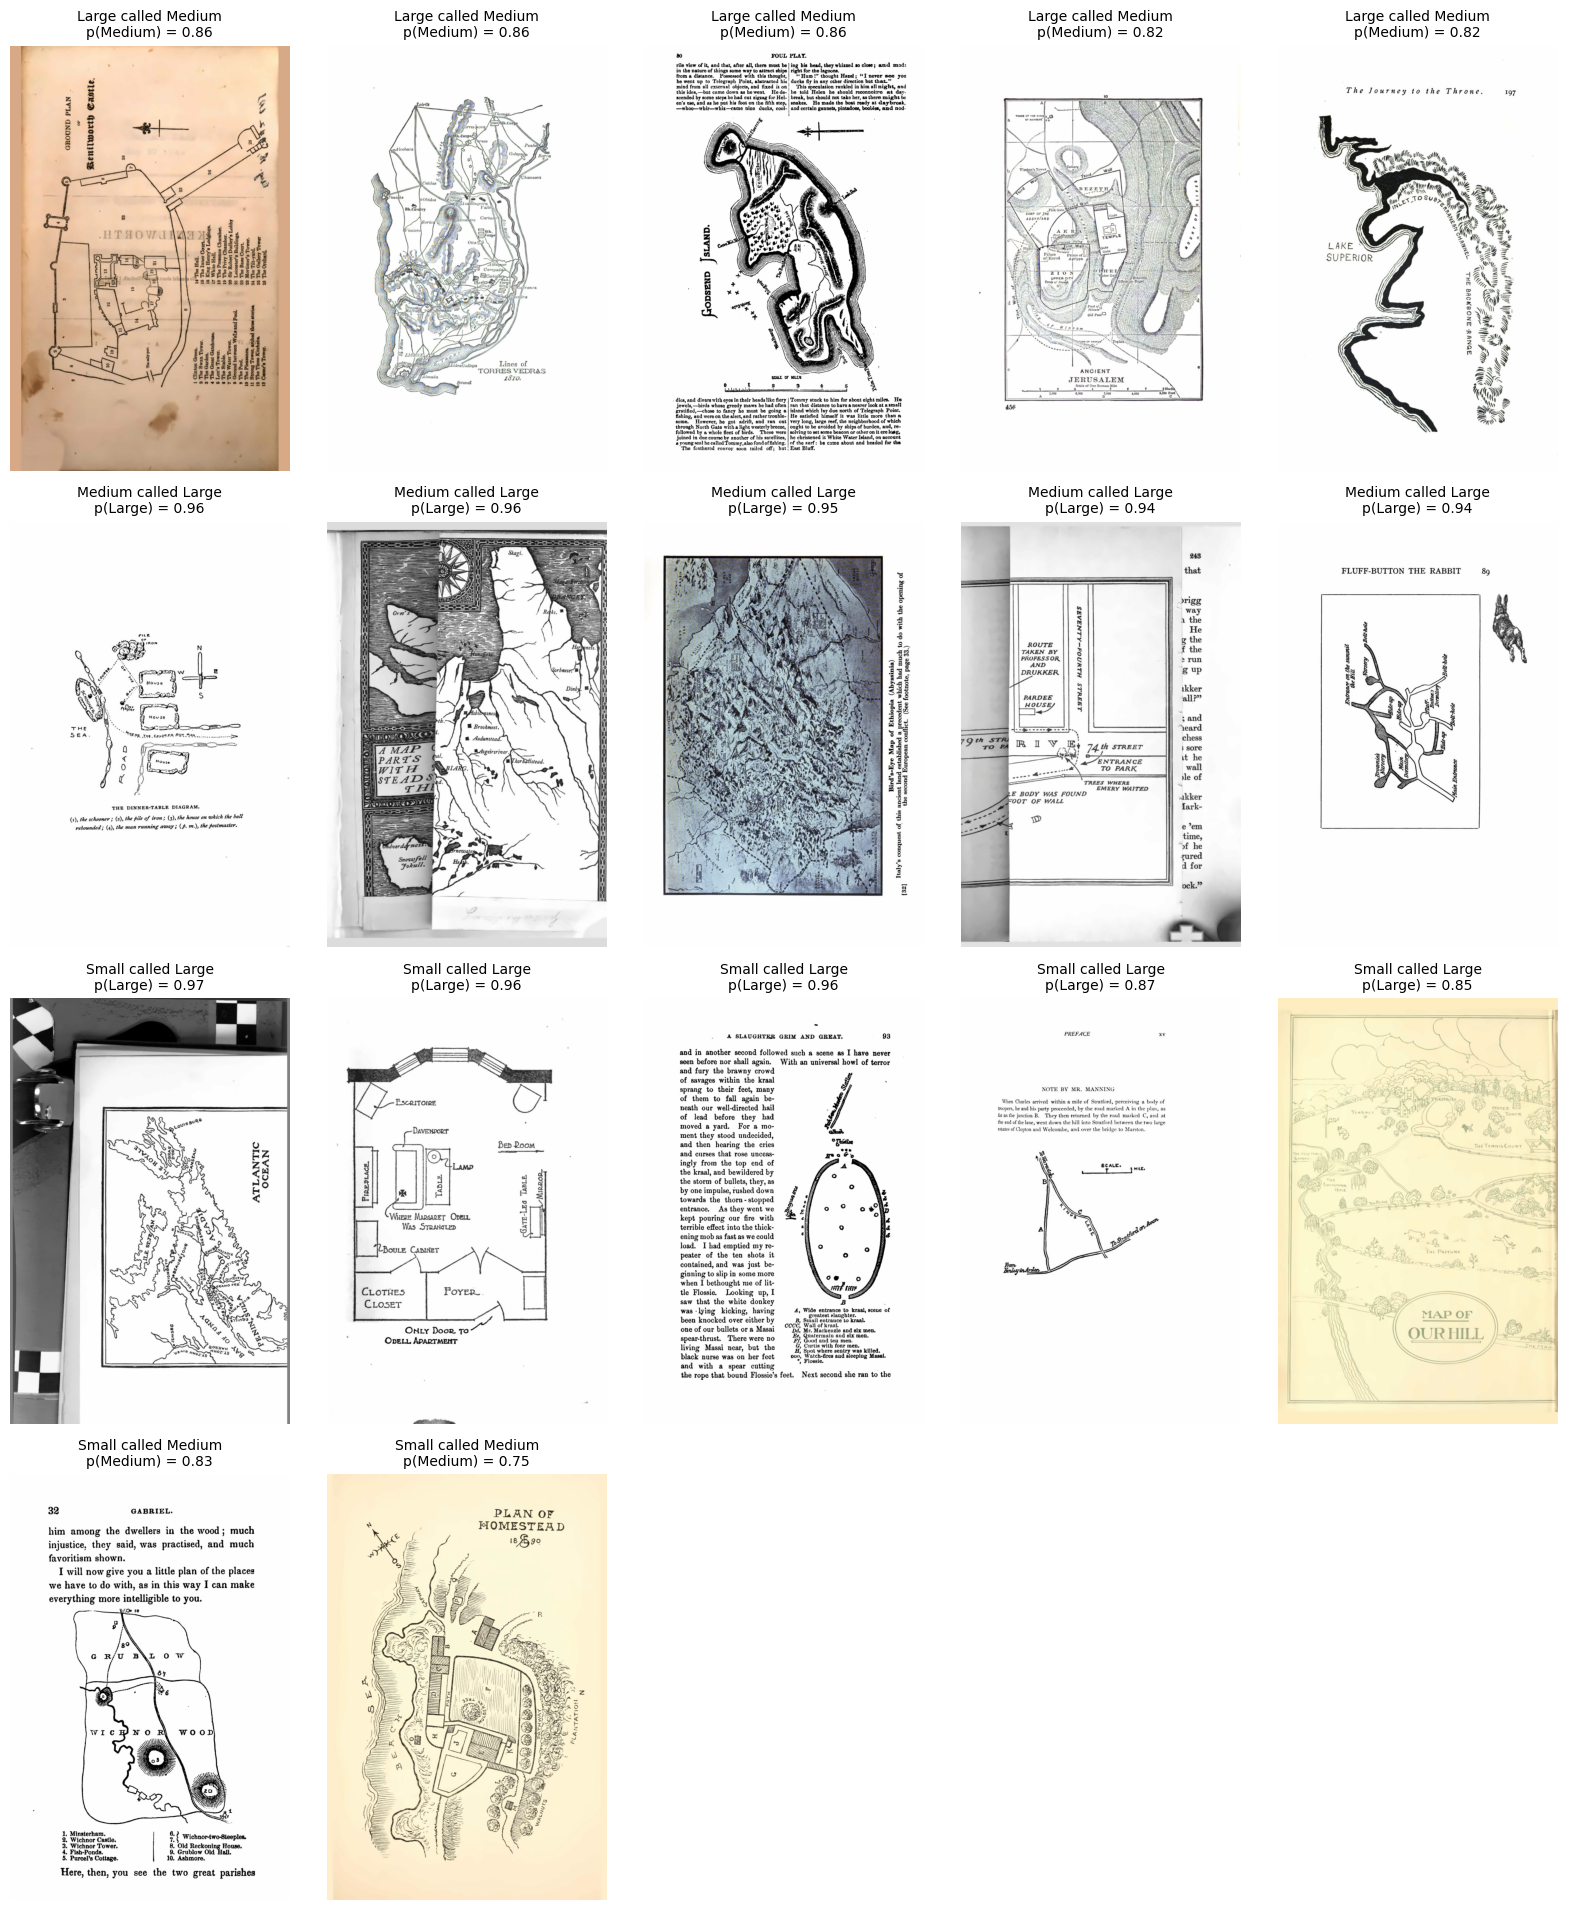

In [27]:
test_proba = final_model.predict_proba(X["test"])   # probability of each class, per test map
mistakes = [(2, 1), (1, 2), (0, 2), (0, 1)]          # (true class, predicted class)

fig, axes = plt.subplots(len(mistakes), N_GALLERY, figsize=(3.2 * N_GALLERY, 4.8 * len(mistakes)))
for row, (true_class, predicted_class) in enumerate(mistakes):
    found = np.where((y["test"] == true_class) & (test_pred == predicted_class))[0]
    found = found[np.argsort(-test_proba[found, predicted_class])][:N_GALLERY]   # most confident first
    print(f"{CLASS_NAMES[true_class]} called {CLASS_NAMES[predicted_class]}: "
          f"{((y['test'] == true_class) & (test_pred == predicted_class)).sum()} test maps")
    for col in range(N_GALLERY):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(found):
            i = found[col]
            with Image.open(PROC / splits["test"]["path"][i]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{CLASS_NAMES[true_class]} called {CLASS_NAMES[predicted_class]}\n"
                         f"p({CLASS_NAMES[predicted_class]}) = {test_proba[i, predicted_class]:.2f}", fontsize=10)
plt.tight_layout()
plt.show()

In [28]:
# Is the model wrong more often on maps whose labels are uncertain?
test_rows = splits["test"].assign(correct=(test_pred == y["test"]))
for column in ["label_conflict", "fictionality"]:
    if column in test_rows.columns:
        table = (test_rows.groupby(column)["correct"].agg(["count", "mean"])
                 .rename(columns={"count": "test maps", "mean": "share correct"}))
        print(f"By {column}:")
        display(table.round(3))
    else:
        print(f"manifest.csv has no {column} column - skipped")

By label_conflict:


,test maps,share correct
label_conflict,,
False,277,0.621
True,13,0.231


By fictionality:


,test maps,share correct
fictionality,,
fictional,103,0.505
real,187,0.658


**How to read this.** Look for what the confident mistakes have in common: a lot of body text or captions on the page, an inset map, very dense hatching, an unusual drawing style. Patterns here are the best evidence for *why* some categories work better than others, and for what to try next (for example, cropping each page to the map itself). In the label table, a much lower share correct for `label_conflict` maps means part of the error comes from uncertain labels.

**On the 11/12 run** several of the most confident mistakes look like **label errors**, with the model right. Judging scale by eye from the maps' titles, about 5 of the 17 maps shown are mislabeled:
- *Labeled Large, called Medium:* a plan of ancient Jerusalem (a city) and a ground plan of Kenilworth Castle (a building, so Small).
- *Labeled Medium, called Large:* a map of part of Iceland and a bird's-eye map of Ethiopia - region and country scale.
- *Labeled Small, called Large:* a map of the Atlantic coast, region scale (the scan also shows a color calibration card).

A few are ambiguous: an island map printed inside a page of text, a "dinner-table diagram" of a few houses by the sea, a rabbit warren in a children's book, and a plan of two parishes ("Grublow" and "Wichnor Wood"). The rest look like genuine mistakes, and they share a few traits:
- *Building and estate plans called Large or Medium:* an apartment floor plan was called Large with p = 0.96, and a "Plan of Homestead, 1890" was called Medium.
- *Text-heavy pages:* a kraal plan inside a page of text and a route sketch under a mostly-text "Note by Mr. Manning" (both labeled Small, called Large), and a city-street plan beside body text (called Large).
- *Faint or yellowed scans:* a faint "Map of Our Hill" (called Large).
- *Regional maps called Medium:* the Lines of Torres Vedras and a lake-and-river map ("The Journey to the Throne"), both drawn with roads or rivers at a size a town plan could have.

The label table agrees: the 13 test maps whose scans got different labels from Gemini were classified correctly only 23% of the time, against 62% for the other 277. Maps of fictional places were right 50% of the time, against 66% for real ones, perhaps because invented places are drawn in freer styles. One caveat: the gallery shows the *most confident* mistakes, which is where label errors pile up, so this does not mean that a third of all 115 errors are label errors. It does mean the labels themselves cap the score.

## 13. Correcting for the class mix

This section tests the explanation in section 10 for why the errors lean toward the rarer classes. The only new parameters are the class offsets below, and they are tuned on the val set only; the test set just scores the result.

**The idea.** The model was trained on rows rebalanced to 33 / 33 / 33% (Small / Medium / Large), but val and test maps come in at about 9 / 18 / 73%. Logistic regression's probabilities reflect the class mix it was trained on, so it over-predicts the rarer classes. Bayes' rule gives the fix: multiply each class's probability by (real share / training share). In log terms that is one fixed **offset** per class, added to the scores before picking the most likely class. Only the differences between the offsets matter, so Large's is kept at 0, and a negative offset means "predict this class less often".

Three versions, all using the same fitted model from section 10 (nothing is refit, and the correction costs nothing at inference):
1. **Original:** section 10's predictions (offsets 0, 0).
2. **Prior correction:** offsets set by the two class mixes - the real mix from one row per train map, the training mix from all train rows. No knobs, so nothing is tuned.
3. **Tuned offsets:** the Small and Medium offsets chosen on val from a grid (`OFFSET_GRID`). With only 26 Small maps in val, the best grid point partly wins by luck, so the same one-SE rule as section 9 applies: among offsets within one SE of the best val macro-F1, take the simplest - the one closest to no correction (0, 0). The offsets then only move as far from the original model as val supports beyond its noise.

First, a check on **val**: does it show the same over-prediction as test? The correction only makes sense if it does.

,val predicted,val actual,test predicted,test actual
Small,38,26,42,25
Medium,51,53,64,53
Large,203,213,184,212


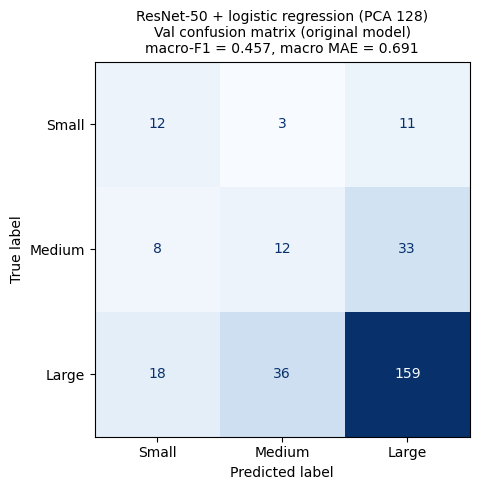

In [29]:
# The check: predicted vs. actual counts per class, on val (and test, for comparison)
display(pd.DataFrame({"val predicted": np.bincount(val_pred, minlength=3),
                      "val actual": np.bincount(y["val"], minlength=3),
                      "test predicted": np.bincount(test_pred, minlength=3),
                      "test actual": np.bincount(y["test"], minlength=3)}, index=CLASS_NAMES))

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y["val"], val_pred, labels=[0, 1, 2]), display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"ResNet-50 + logistic regression ({pca_label(FINAL_DIMS)})\nVal confusion matrix (original model)\n"
             f"macro-F1 = {val_scores['macro_f1']:.3f}, macro MAE = {val_scores['macro_mae']:.3f}", fontsize=10)
plt.tight_layout()
plt.show()

Class mix the model learned from (Small, Medium, Large): [0.333 0.333 0.333]   real mix: [0.087 0.183 0.73 ]
Prior correction offsets (Small, Medium): -2.13, -1.39
Best on val: -0.40, +0.30 (val macro-F1 0.512, SE 0.037)
Tuned (one-SE, closest to no correction): +0.00, +0.10 (val macro-F1 0.476)


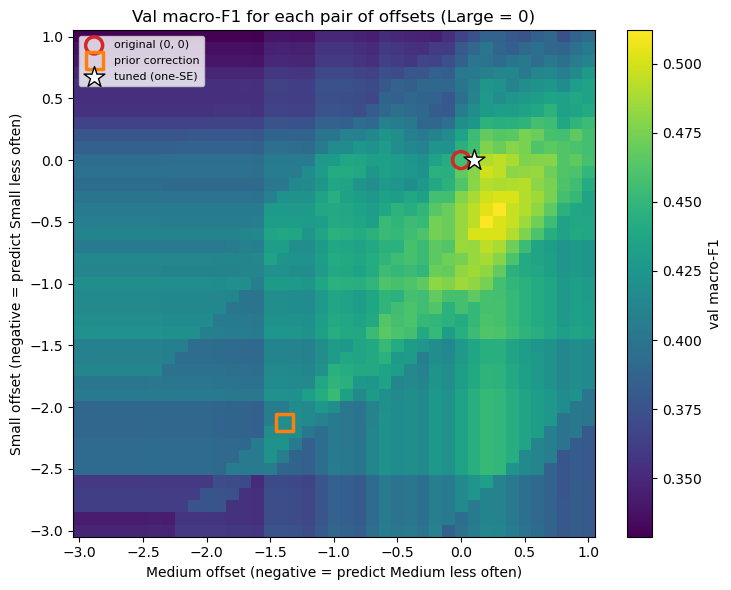

In [30]:
# Class mixes. With balanced class weighting every class gets the same total weight, so the model "sees" 1/3 each.
real_mix = np.bincount(y_train_maps, minlength=3) / len(y_train_maps)    # one row per train map = the real mix
if FINAL_WEIGHTING == "balanced":
    train_mix = np.full(3, 1 / 3)
else:
    train_mix = np.bincount(y["train"], minlength=3) / len(y["train"])   # all train rows = what the model learned from

# Bayes' rule in log terms, shifted so Large's offset is 0
prior_offset = np.log(real_mix / train_mix)
prior_offset = prior_offset - prior_offset[2]

log_proba = {split: np.log(np.clip(final_model.predict_proba(X[split]), 1e-12, None)) for split in ["val", "test"]}


def predict_with(offset, split):
    # Most likely class after adding one offset per class to the log-probabilities
    return np.argmax(log_proba[split] + np.asarray(offset), axis=1)


assert np.array_equal(predict_with(np.zeros(3), "test"), test_pred)   # offsets of 0 = the original model

# Search the grid of (Small, Medium) offsets on val
grid_f1 = np.zeros((len(OFFSET_GRID), len(OFFSET_GRID)))   # rows = Small offset, columns = Medium offset
for i, small_offset in enumerate(OFFSET_GRID):
    for j, medium_offset in enumerate(OFFSET_GRID):
        grid_f1[i, j] = macro_f1_fast(y["val"], predict_with([small_offset, medium_offset, 0.0], "val"))

best_i, best_j = np.unravel_index(np.argmax(grid_f1), grid_f1.shape)
best_offset = np.array([OFFSET_GRID[best_i], OFFSET_GRID[best_j], 0.0])
best_val_pred = predict_with(best_offset, "val")
best_se = np.std([macro_f1_fast(y["val"][rows], best_val_pred[rows]) for rows in val_resamples])

# One-SE rule: of the offsets within one SE of the best, the simplest = the one closest to no correction (0, 0)
small_grid, medium_grid = np.meshgrid(OFFSET_GRID, OFFSET_GRID, indexing="ij")
distance_to_original = np.hypot(small_grid, medium_grid)
tied = grid_f1 >= grid_f1[best_i, best_j] - best_se
pick_i, pick_j = np.unravel_index(np.argmin(np.where(tied, distance_to_original, np.inf)), grid_f1.shape)
tuned_offset = np.array([OFFSET_GRID[pick_i], OFFSET_GRID[pick_j], 0.0])

print("Class mix the model learned from (Small, Medium, Large):", train_mix.round(3), "  real mix:", real_mix.round(3))
print(f"Prior correction offsets (Small, Medium): {prior_offset[0]:+.2f}, {prior_offset[1]:+.2f}")
print(f"Best on val: {best_offset[0]:+.2f}, {best_offset[1]:+.2f} (val macro-F1 {grid_f1[best_i, best_j]:.3f}, SE {best_se:.3f})")
print(f"Tuned (one-SE, closest to no correction): {tuned_offset[0]:+.2f}, {tuned_offset[1]:+.2f} "
      f"(val macro-F1 {grid_f1[pick_i, pick_j]:.3f})")

# Val macro-F1 over the grid, with the three versions marked
step = OFFSET_GRID[1] - OFFSET_GRID[0]
edges = (OFFSET_GRID[0] - step / 2, OFFSET_GRID[-1] + step / 2)
fig, ax = plt.subplots(figsize=(7.5, 6))
picture = ax.imshow(grid_f1, origin="lower", cmap="viridis", aspect="auto", extent=(*edges, *edges))
fig.colorbar(picture, ax=ax, label="val macro-F1")
ax.scatter(0, 0, marker="o", s=150, facecolors="none", edgecolors="tab:red", linewidths=2.5, label="original (0, 0)")
ax.scatter(prior_offset[1], prior_offset[0], marker="s", s=150, facecolors="none", edgecolors="tab:orange",
           linewidths=2.5, label="prior correction")
ax.scatter(tuned_offset[1], tuned_offset[0], marker="*", s=250, c="white", edgecolors="black", label="tuned (one-SE)")
ax.set_xlabel("Medium offset (negative = predict Medium less often)")
ax.set_ylabel("Small offset (negative = predict Small less often)")
ax.set_title("Val macro-F1 for each pair of offsets (Large = 0)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

,Small offset,Medium offset,val macro-F1,val macro MAE,test macro-F1,test macro MAE,test accuracy,"test predicted (S, M, L)",test gain vs. original (paired 95%)
version,,,,,,,,,
original,0.000,0.000,0.457,0.691,0.461,0.744,0.603,"(42, 64, 184)",-
prior correction,-2.129,-1.386,0.419,0.840,0.365,0.926,0.714,"(3, 20, 267)",-0.097 (-0.171 to -0.023)
tuned offsets (one-SE),0.000,0.100,0.476,0.671,0.447,0.740,0.586,"(37, 76, 177)",-0.015 (-0.039 to +0.005)


,test F1: original,test F1: prior correction,test F1: tuned offsets (one-SE)
Small,0.269,0.071,0.258
Medium,0.393,0.192,0.372
Large,0.722,0.831,0.710


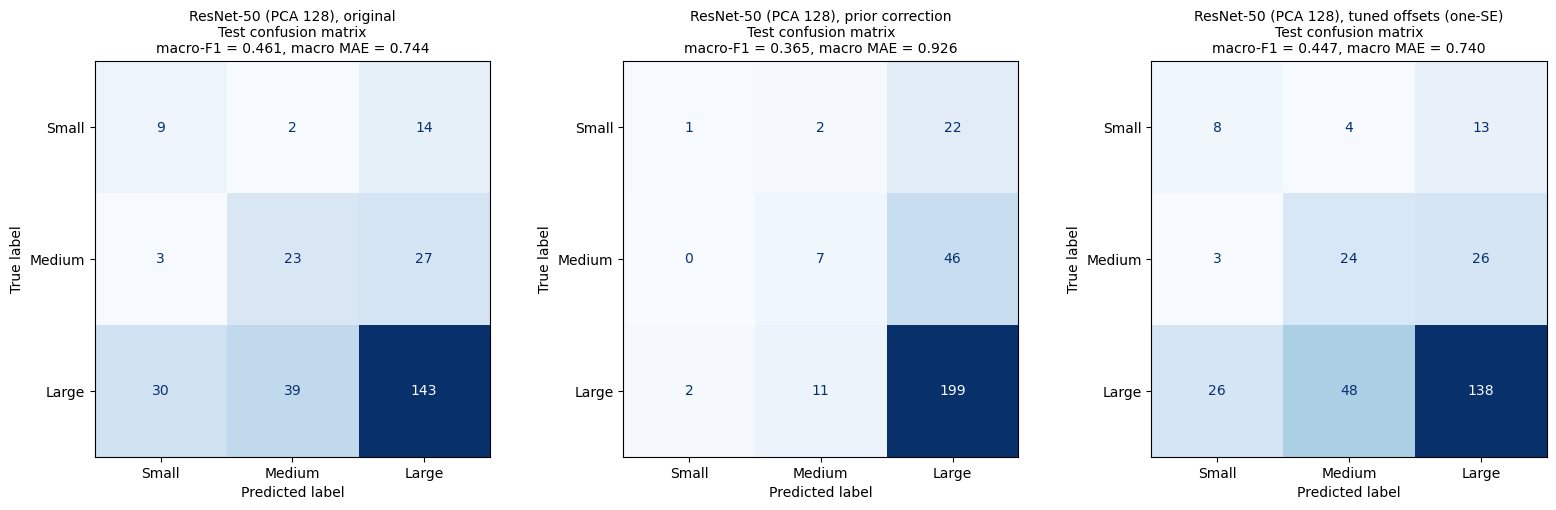

In [31]:
# The three versions on val and test
versions = {"original": np.zeros(3), "prior correction": prior_offset, "tuned offsets (one-SE)": tuned_offset}
version_rows, test_preds = [], {}
for name, offset in versions.items():
    version_val_pred, version_test_pred = predict_with(offset, "val"), predict_with(offset, "test")
    test_preds[name] = version_test_pred
    version_rows.append({"version": name, "Small offset": offset[0], "Medium offset": offset[1],
                         "val macro-F1": macro_f1_fast(y["val"], version_val_pred),
                         "val macro MAE": macro_mae(y["val"], version_val_pred),
                         "test macro-F1": macro_f1_fast(y["test"], version_test_pred),
                         "test macro MAE": macro_mae(y["test"], version_test_pred),
                         "test accuracy": accuracy_score(y["test"], version_test_pred),
                         "test predicted (S, M, L)": str(tuple(int(n) for n in np.bincount(version_test_pred, minlength=3)))})
followup = pd.DataFrame(version_rows).set_index("version")

# Paired bootstrap on the test maps: each corrected version vs. the original, on the same draws
rng = np.random.default_rng(SEED)
gains = {name: [] for name in versions if name != "original"}
for _ in range(N_BOOTSTRAP):
    rows = rng.integers(0, n_test, n_test)
    original_f1 = macro_f1_fast(y["test"][rows], test_pred[rows])
    for name in gains:
        gains[name].append(macro_f1_fast(y["test"][rows], test_preds[name][rows]) - original_f1)
followup["test gain vs. original (paired 95%)"] = "-"
for name, draws in gains.items():
    point = followup.loc[name, "test macro-F1"] - followup.loc["original", "test macro-F1"]
    followup.loc[name, "test gain vs. original (paired 95%)"] = (
        f"{point:+.3f} ({np.percentile(draws, 2.5):+.3f} to {np.percentile(draws, 97.5):+.3f})")
display(followup.round(3))

display(pd.DataFrame({f"test F1: {name}": f1_score(y["test"], pred, labels=[0, 1, 2], average=None, zero_division=0)
                      for name, pred in test_preds.items()}, index=CLASS_NAMES).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, pred) in zip(axes, test_preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y["test"], pred, labels=[0, 1, 2]), display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"ResNet-50 ({pca_label(FINAL_DIMS)}), {name}\nTest confusion matrix\n"
                 f"macro-F1 = {macro_f1_fast(y['test'], pred):.3f}, macro MAE = {macro_mae(y['test'], pred):.3f}", fontsize=10)
plt.tight_layout()
plt.show()

**How to read this.**
- **The val check (first table):** if the original model over-predicts the same class on val as on test, the over-prediction is a property of the model, not of one test set.
- **Prior correction:** it should cut the errors toward the rarer classes (compare the test confusion matrices) and raise Large's F1. The likely cost is that Small and Medium, which macro-F1 weighs as much as Large, end up predicted far too rarely. Whether macro-F1 goes up depends on which effect is bigger.
- **Tuned offsets:** they were picked on val, so their val score flatters them; compare them on test. If they stay at (or next to) 0, 0, val found no gain from correcting that is bigger than its noise. If the paired interval of a gain includes 0, that correction doesn't reliably help on these test maps.

**On the 11/12 run** the training mix is 33 / 33 / 33%, and the val check shows the over-prediction is mostly of Small: the original model predicted Small 38 times for 26 Small val maps (42 for 25 on test), while Medium was about right on val (51 for 53) and over on test (64 for 53). A simple offset still doesn't fix it:
- *Prior correction:* the full Bayes shift (offsets of -2.13 for Small and -1.39 for Medium) made the model predict almost only Large: 3 Small and 20 Medium predictions on test. Accuracy rose to 0.714, but macro-F1 fell to 0.365 (0.419 on val), a paired loss of 0.097 (95% interval -0.171 to -0.023).
- *Tuned offsets:* the best pair on val lowers Small and raises Medium (Small -0.4, Medium +0.3: val 0.512, SE 0.037), which fits the over-prediction of Small. The one-SE rule kept Small at 0 and moved Medium only to +0.1 (val 0.476, against 0.457 for the original). On test that version scored 0.447 against 0.461, a paired change of -0.015 (95% interval -0.039 to +0.005): no reliable gain.

So the class mix explains the direction of the errors, but correcting it after training costs more than it saves - as on the 11/4 run, when the over-predicted class was Medium. The likely reason is that the model's evidence for each map is weak, so its probabilities stay close to the training mix, and the full prior correction overwhelms what the image says. Part of the confusion is also label noise (section 12), which no offset can fix. The original model from section 10 stays the final model: this section is an analysis of the class-mix explanation, not part of choosing the model.

## 14. Efficiency

Costs for the efficiency-vs-accuracy comparison, on the same basis as `3-simple_model` (CPU, one thread, one image at a time for the features). The network is never trained, so its cost is only running it:
- **Training cost** = embedding every training image + fitting the scaler, PCA and logistic regression
- **Inference cost per image** = loading, preparing and embedding one image + its share of the prediction time

The bulk run's time (on a GPU, if there is one) is shown too, as what the pipeline actually costs on the best hardware available.

The plot shows every setting from the search: val macro-F1 against fitting time. It shows how much the classifier settings change the cost - compared with the time spent in the network.

,item,value,note
0,"embed 1 image (CPU, 1 thread)",158.7 ms,"load + prepare 10.8 ms, network 147.9 ms"
1,embed 1 image (bulk run on cuda),16.1 ms,batches of 32
2,"embed all 5001 training images (CPU, 1 thread)",793.6 s,
3,fit scaler + PCA + logistic regression,0.36 s,PCA 128
4,training cost (embed train + fit),794.0 s,used in the comparison
5,inference cost per image (embed + predict),158.7 ms,used in the comparison


,feature + classifier,test macro-F1,test macro MAE,training cost (s),inference (ms per image),inference cost vs. simple
0,simple (ink) + logistic regression,0.383,0.794,112.047,22.404,1.000
1,ResNet-50 + logistic regression (PCA 128),0.461,0.744,793.978,158.698,7.083


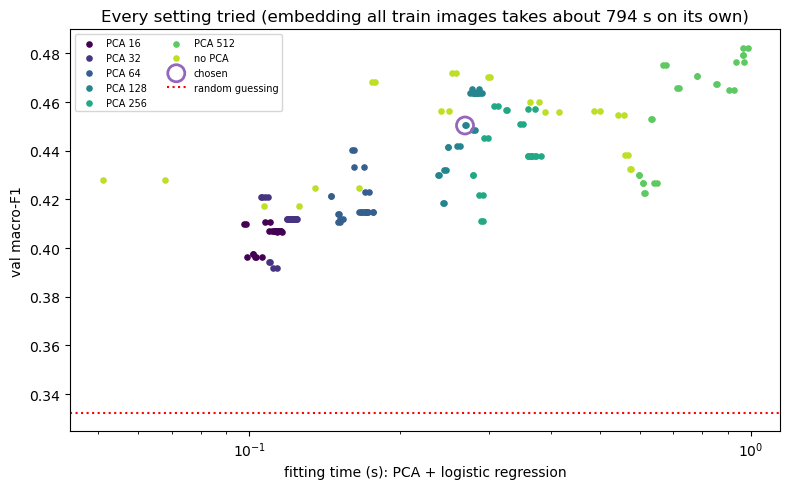

In [32]:
n_train = len(y["train"])
embed_train_seconds = embed_ms_per_image / 1000 * n_train
train_cost_seconds = embed_train_seconds + fit_seconds
inference_ms = embed_ms_per_image + 1000 * predict_seconds / n_test

cost_table = pd.DataFrame([
    {"item": f"embed 1 image (CPU, {TIMING_CPU_THREADS} thread)", "value": f"{embed_ms_per_image:.1f} ms",
     "note": f"load + prepare {prep_ms:.1f} ms, network {network_ms:.1f} ms"},
    {"item": f"embed 1 image (bulk run on {extract_device['train']})", "value": f"{bulk_ms_per_image:.1f} ms",
     "note": f"batches of {BATCH_SIZE}"},
    {"item": f"embed all {n_train} training images (CPU, {TIMING_CPU_THREADS} thread)", "value": f"{embed_train_seconds:.1f} s", "note": ""},
    {"item": "fit scaler + PCA + logistic regression", "value": f"{fit_seconds:.2f} s", "note": pca_label(FINAL_DIMS)},
    {"item": "training cost (embed train + fit)", "value": f"{train_cost_seconds:.1f} s", "note": "used in the comparison"},
    {"item": "inference cost per image (embed + predict)", "value": f"{inference_ms:.1f} ms", "note": "used in the comparison"},
])
display(cost_table)

# Accuracy vs. cost, next to the simple features (3-simple_model, loaded in section 11)
tradeoff = pd.DataFrame([
    {"feature + classifier": f"simple ({simple_results['feature']}) + logistic regression",
     "test macro-F1": simple_results["test_macro_f1"], "test macro MAE": simple_results["test_macro_mae"],
     "training cost (s)": simple_results["train_cost_seconds"], "inference (ms per image)": simple_results["inference_ms_per_image"]},
    {"feature + classifier": f"ResNet-50 + logistic regression ({pca_label(FINAL_DIMS)})",
     "test macro-F1": test_scores["macro_f1"], "test macro MAE": test_scores["macro_mae"],
     "training cost (s)": train_cost_seconds, "inference (ms per image)": inference_ms},
])
tradeoff["inference cost vs. simple"] = tradeoff["inference (ms per image)"] / simple_results["inference_ms_per_image"]
display(tradeoff.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
for n_dims, color in zip(PCA_DIMS, size_colors):
    rows = search[search["pca_dims"] == n_dims]
    ax.scatter(rows["fit_seconds"], rows["val_macro_f1"], s=14, color=color, label=pca_label(n_dims))
ax.scatter([chosen["fit_seconds"]], [chosen["val_macro_f1"]], s=150, facecolors="none", edgecolors="tab:purple",
           linewidths=2, label="chosen")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
ax.set_xscale("log")
ax.set_xlabel("fitting time (s): PCA + logistic regression")
ax.set_ylabel("val macro-F1")
ax.set_title(f"Every setting tried (embedding all train images takes about {embed_train_seconds:.0f} s on its own)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

**On the 11/12 run** the network dominated the cost: embedding one image took 158.7 ms on one CPU thread (147.9 ms of it the network itself, 10.8 ms loading and preparing the image), about 7x the 22.4 ms the simple `ink` feature takes. Embedding all 5,001 training images took about 794 s, against 0.36 s to fit the scaler, PCA and regression, so the training cost is 794 s against 112 s for the simple features. On the GPU, the bulk run took 16.1 ms per image. (Timings move by a few percent between runs, and they only compare fairly when every notebook runs on the same machine.)

**The trade-off.** So far the simple features are the efficient option and ResNet-50 the accurate one: about 7x the CPU cost for +0.08 macro-F1 and 0.05 fewer steps off. Within this notebook, the classifier settings barely change the cost (every fit takes about a second or less), so:
- **Optimizing for accuracy** means picking the best setting on val - and, beyond this notebook, a bigger input or a stronger network (`5-DINOv2` and `6-DINOv3`).
- **Optimizing for efficiency** mostly means making the network cheaper: a smaller network (ResNet-18 needs about 2x fewer computations), a smaller input width, a GPU, or batching at inference. A smaller PCA (16 components scored 0.411 on val against 0.450 for 128) makes the classifier tiny, but that matters little next to the network - it would matter more if the saved embeddings were reused by a slower classifier, such as an SVM.

## 15. Save the results

Three files in `data/results/`, for the report and the comparisons across notebooks:
- `4-pretrained_feature.json`: the chosen setting, val and test scores, per-class F1 and costs
- `4-pretrained_feature_search.csv`: every setting from the search in section 9
- `4-pretrained_feature_test_predictions.csv`: this model's prediction for every test map, so later notebooks (an SVM, DINO) can run the same paired test against it

Section 13's three versions (original, prior correction, tuned offsets) are saved under `class_mix_correction`.

The embeddings themselves are already in `data/features/` (section 7).

In [33]:
results = {
    "notebook": "4-pretrained_feature",
    "run_date": time.strftime("%Y-%m-%d"),
    "feature": "ResNet-50 ImageNet embedding (penultimate layer, 2048)",
    "classifier": "logistic regression",
    "weights": str(WEIGHTS),
    "embed_size": list(EMBED_SIZE),
    "pca_dims": FINAL_DIMS,
    "class_weight": FINAL_WEIGHTING,
    "C": FINAL_C,
    "selection_rule": SELECTION_RULE,
    "split_fingerprint": SPLIT_FINGERPRINT,
    "val_macro_f1": float(val_scores["macro_f1"]),
    "val_macro_mae": float(val_scores["macro_mae"]),
    "test_macro_f1": float(test_scores["macro_f1"]),
    "test_macro_f1_95ci": [float(model_low), float(model_high)],
    "test_macro_mae": float(test_scores["macro_mae"]),
    "test_macro_mae_95ci": [float(mae_low), float(mae_high)],
    "test_accuracy": float(test_scores["accuracy"]),
    "test_balanced_acc": float(test_scores["balanced_acc"]),
    "test_f1_per_class": {name: float(f) for name, f in zip(CLASS_NAMES, per_class_f1)},
    "test_two_step_errors": two_step_errors,
    "share_of_random_runs_as_good": float(share_as_good),
    "embed_ms_per_image_cpu": float(embed_ms_per_image),
    "embed_ms_per_image_bulk": float(bulk_ms_per_image),
    "bulk_device": extract_device["train"],
    "fit_seconds": float(fit_seconds),
    "train_cost_seconds": float(train_cost_seconds),
    "inference_ms_per_image": float(inference_ms),
    "class_mix_correction": {   # section 13: offsets tuned on val only
        name: {"offsets_small_medium": [float(o) for o in versions[name][:2]],
               "val_macro_f1": float(followup.loc[name, "val macro-F1"]),
               "test_macro_f1": float(followup.loc[name, "test macro-F1"]),
               "test_macro_mae": float(followup.loc[name, "test macro MAE"])}
        for name in versions},
}
(RESULTS_DIR / "4-pretrained_feature.json").write_text(json.dumps(results, indent=2))
search.to_csv(RESULTS_DIR / "4-pretrained_feature_search.csv", index=False)
pd.DataFrame({"path": splits["test"]["path"], "label": y["test"], "pred": test_pred}).to_csv(
    RESULTS_DIR / "4-pretrained_feature_test_predictions.csv", index=False)
print("Saved 4-pretrained_feature.json, 4-pretrained_feature_search.csv and 4-pretrained_feature_test_predictions.csv in",
      RESULTS_DIR)

Saved 4-pretrained_feature.json, 4-pretrained_feature_search.csv and 4-pretrained_feature_test_predictions.csv in /home/uselessbian/281/281project/data/results


## 16. Discussion and limitations

**Why this feature was chosen.** Map scale is mostly a matter of layout and line structure (see the project plan): walls at right angles, street grids, coastlines, blocks of text. A CNN pretrained on ImageNet has general detectors for exactly these kinds of patterns (edges, grids, textures, curves), learned from 1.28 million photos - far more data than our 1,358 training maps could teach a network from scratch. Taking the penultimate layer gives a fixed 2,048-number description of each page that any of the course's classifiers can use. It complements the simple features (brightness, ink, color), which say nothing about structure, and the hand-designed features, which encode our own guesses about structure.

**What it achieved (11/12 run).** Test macro-F1 0.461 (95% interval 0.395 - 0.525), clearly above random guessing (0.33; no random run matched it) and 0.079 above the simple features (`ink`, 0.383), a gain the paired test in section 11 confirms, though its lower end is close to 0 (95% interval +0.007 to +0.145). Macro MAE 0.74 steps, against 0.94 for random guessing and 0.79 for the simple features.

**Why it works better for some categories than others.**
- **Small (F1 0.27, up from 0.19 with the simple features).** Floor plans and estates are drawn with straight walls, right angles and room grids. ImageNet's filters respond to grid-like, man-made patterns - Small was the only class whose top ImageNet guesses included crossword puzzle and slide rule (section 8b) - so the embedding sees some of the structure the simple features couldn't. It is still the hardest class: only 118 train maps (augmented to 1,667 rows, about 14 per map, but near-copies add little new information), only 25 test maps (so its F1 is the noisiest), and 14 of the 25 were called Large, the worst possible mistake. The model also over-commits to Small: 42 predictions for 25 Small maps, 30 of them Large maps.
- **Medium (F1 0.39).** Recall is moderate (23 of 53 found) and precision poor: 64 Medium predictions for 53 Medium maps. A town plan shares street grids, buildings and dense labels with a crowded regional map, and with a large estate plan.
- **Large (F1 0.72, no better than guessing).** 39 of the 212 Large maps were called Medium and 30 called Small. The class mix explains the direction: training rows were rebalanced to 1,667 per class, so the regression learned that Small and Medium are as common as Large, while in val and test they are about 8x and 4x rarer, and val shows the same over-prediction of Small. But correcting for the mix made things worse (section 13), so the deeper problem is that the embedding separates Large from the other classes only weakly. Large also covers the most drawing styles - coastlines, mountains, sea, decorative borders - so it has no single look.
- **Labels, for every class.** Many of the model's most confident mistakes are mislabeled maps that it got right (section 12): region and country maps labeled Small or Medium, a castle ground plan labeled Large. The 13 test maps with conflicting Gemini labels were right only 23% of the time. Small is hit hardest, since each mislabeled map is 4% of its 25 test maps.

**Generalizability.** Test (0.461) came in at val's level (0.457), so the tuning did not overfit the val set. Two things helped: bootstrap resamples of the validation data measured how noisy each val score was (SE about 0.033), and the one-SE rule chose the simplest setting tied with the best, instead of the top val score (PCA 512 with C = 22, train macro-F1 0.908). The test interval is still wide (0.395 - 0.525) because test has only 25 Small maps.

**More augmentation didn't help (11/4 vs. 11/12 run).** Both runs used the same split; only `2-augment` changed, from rebalancing to 590 / 1,240 / 1,240 training rows (tilts up to 2 degrees) to 1,667 rows per class (tilts up to 5 degrees, plus gamma and paper warmth). With the larger set the best val score fell from 0.507 to 0.482, the chosen setting's val from 0.473 to 0.457, and test from 0.481 to 0.461; macro MAE rose from 0.65 to 0.74 and two-step errors from 20 to 44. The macro-F1 drops are within one SE, so this is "no gain" rather than "clearly worse", but the shift in errors is clear: the over-prediction moved from Medium (106 predictions for 53 maps) to Small (42 for 25). Extra copies of 118 floor plans act mostly as extra weight on Small, not as new information. Two things changed at once (the class counts and the transforms), so these two runs can't say which one caused the change.

**Why fixed splits, not cross-validation.** Pooling train and val for cross-validation would tune on about 20% more maps and keep more un-augmented Small scans, but val maps get no rescans or augmented copies, so preprocessing and augmentation would have to be redone and every notebook rerun. We kept fixed train / val / test splits instead, and measured the val set's noise with bootstrap resamples and the one-SE rule.

**Limitations.**
- **Domain gap.** ImageNet is color photos of objects; our maps are old line drawings on paper (section 5's histograms). The network's last layers are tuned to recognize objects, and to it most of our pages are "envelopes" and "book jackets" (section 8b).
- **Resolution.** Shrinking 672-pixel-wide pages to 224 pixels wide makes thin lines faint and small text unreadable. Map text ("Hall", "Main St.", "Ocean") is a strong scale cue that the network can barely see.
- **The whole page is embedded.** Body text, captions and page numbers around a map change its embedding, so the same kind of map looks different depending on how it was printed.
- **Averaging away position.** The global average pool keeps how much of each pattern there is, not where it is, so layout cues such as "a legend box in a corner" are blurred together with everything else.
- **Frozen weights.** Nothing in the network was adapted to maps. Fine-tuning would probably help but needs a GPU and more data, and risks overfitting 1,358 maps.
- **Class mix mismatch.** Rebalancing the training rows helps the model notice Small and Medium, but it also teaches the wrong class frequencies, and a correction afterwards couldn't undo that without losing the rarer classes (section 13).
- **Augmented copies.** Flipped and slightly shifted copies get very similar embeddings, so the extra training rows add less new information than their number suggests, and they inflate the train scores in section 9.
- **Labels and sample size.** The labels come from Gemini, with real disagreement on 33% of the maps with several scans, and section 12 found clear label errors among the most confident mistakes (region maps labeled Small, a castle ground plan labeled Large). Val and test have only about 25 Small maps each, so per-class scores, especially for Small, are noisy. Choosing among 182 settings on one val set can still be optimistic even with the one-SE rule.
- **t-SNE** pictures depend on perplexity and the random seed; only the neighborhoods carry meaning.

**Ways to improve.**
- **Re-check the labels** of the maps with conflicting Gemini labels, ideally all of them rather than only the ones the model got wrong, so the check doesn't favor the model. Then the scores would measure the model rather than the labels.
- **Class mix.** Section 13's correction after training didn't help, and going from milder rebalancing (11/4) to equal class counts (11/12) didn't either. Milder rebalancing still (fewer copies of Small and Medium), or class weights that restore part of the real mix, compared on val, is the next thing to try.
- **Crop to the map** (the object-detection step planned for preprocessing), so body text and captions don't change the embedding.
- Try layer3 (1,024 numbers), or embed at a larger width (448) or as overlapping tiles of the page, so thin lines and text survive.
- Stronger or more suitable pretrained networks: DINOv2 and DINOv3 are in notebooks 5 and 6; CLIP is in the project plan.
- Use the saved embeddings with the second classifier (an SVM) and in combination with the hand-designed features.
- Class activation maps (weighting layer4's channels by the regression's weights) would show which parts of a page push it toward each class.